# **Travel Insurance Claim Prediction**
Capstone Project - Data Science

Tujuan: memprediksi apakah pemegang polis asuransi perjalanan akan mengajukan klaim (`Claim` = Yes/No), lalu mensimulasikan dampak finansialnya dengan *Cost Benefit Simulation*.

## **0. Setup**

In [2]:
import warnings
warnings.filterwarnings("ignore")

# data manipulation
import numpy as np
import pandas as pd

# data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# sklearn
import sklearn
from sklearn import set_config
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, StandardScaler
from sklearn.feature_selection import SelectFpr
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.base import clone
from sklearn.metrics import (make_scorer, precision_recall_curve, auc, recall_score, fbeta_score,
                             ConfusionMatrixDisplay, classification_report)

# models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# outlier handling
from feature_engine.outliers import Winsorizer

# imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss

# agar output transformer tetap berupa DataFrame (nama fitur terjaga sampai SHAP)
set_config(transform_output="pandas")

pd.set_option("display.max_columns", 50)
print("scikit-learn:", sklearn.__version__)

scikit-learn: 1.9.1


## **1. Data Understanding**

In [3]:
df = pd.read_csv("data_travel_insurance.csv")

# Standarisasi nama kolom & target (Claim: No -> 0, Yes -> 1)
df = df.rename(columns={"Commision (in value)": "Commission"})
df["target"] = df["Claim"].map({"No": 0, "Yes": 1})
df = df.drop(columns="Claim")

print("Shape:", df.shape)
df.info()
df.head()

Shape: (44328, 11)
<class 'pandas.DataFrame'>
RangeIndex: 44328 entries, 0 to 44327
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Agency                44328 non-null  str    
 1   Agency Type           44328 non-null  str    
 2   Distribution Channel  44328 non-null  str    
 3   Product Name          44328 non-null  str    
 4   Gender                12681 non-null  str    
 5   Duration              44328 non-null  int64  
 6   Destination           44328 non-null  str    
 7   Net Sales             44328 non-null  float64
 8   Commission            44328 non-null  float64
 9   Age                   44328 non-null  int64  
 10  target                44328 non-null  int64  
dtypes: float64(2), int64(3), str(6)
memory usage: 5.8 MB


,Agency,Agency Type,Distribution Channel,Product Name,Gender,Duration,Destination,Net Sales,Commission,Age,target
0,C2B,Airlines,Online,Annual Silver Plan,F,365,SINGAPORE,216.0,54.0,57,0
1,EPX,Travel Agency,Online,Cancellation Plan,NaN,4,MALAYSIA,10.0,0.0,33,0
2,JZI,Airlines,Online,Basic Plan,M,19,INDIA,22.0,7.7,26,0
3,EPX,Travel Agency,Online,2 way Comprehensive Plan,NaN,20,UNITED STATES,112.0,0.0,59,0
4,C2B,Airlines,Online,Bronze Plan,M,8,SINGAPORE,16.0,4.0,28,0


In [4]:
df.describe()

,Duration,Net Sales,Commission,Age,target
count,44328.000000,44328.000000,44328.000000,44328.000000,44328.000000
mean,49.424292,40.550948,9.707692,39.925600,0.015273
std,109.153961,48.661970,19.625637,13.954926,0.122636
min,-1.000000,-357.500000,0.000000,0.000000,0.000000
25%,9.000000,18.000000,0.000000,35.000000,0.000000
50%,22.000000,26.500000,0.000000,36.000000,0.000000
75%,53.000000,48.000000,11.550000,43.000000,0.000000
max,4881.000000,810.000000,283.500000,118.000000,1.000000


In [5]:
df["target"].value_counts().to_frame("count").assign(percentage=lambda t: (t["count"] / t["count"].sum() * 100).round(2))

,count,percentage
target,,
0,43651,98.47
1,677,1.53


## **2. Data Cleaning**

### *2.1 Identify Missing Value*

In [6]:
# 1. Menghitung jumlah missing value per kolom
missing_count = df.isnull().sum()

# 2. Menghitung persentase missing value per kolom
missing_percentage = round((df.isnull().sum() / len(df)) * 100,2)

# 3. Menggabungkan hasil ke dalam satu DataFrame baru
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percentage
})

# 4. Mengurutkan dari yang terbesar dan menampilkan kolom yang memiliki missing value
missing_df = missing_df.sort_values(by='Missing Count', ascending=False)
missing_df

,Missing Count,Missing Percentage (%)
Gender,31647,71.39
Agency Type,0,0.00
Agency,0,0.00
Distribution Channel,0,0.00
Product Name,0,0.00
Duration,0,0.00
Destination,0,0.00
Net Sales,0,0.00
Commission,0,0.00
Age,0,0.00


In [7]:
# Apakah missing pada Gender acak atau terkait agensi?
gender_by_agency = (df.assign(gender_missing=df["Gender"].isnull())
                      .groupby("Agency")["gender_missing"].agg(["mean", "size"])
                      .rename(columns={"mean": "share_gender_missing", "size": "n_rows"})
                      .sort_values("n_rows", ascending=False))
gender_by_agency.round(3)

,share_gender_missing,n_rows
Agency,,
EPX,1.000,24656
CWT,0.999,5980
C2B,0.000,5753
JZI,0.011,4433
SSI,1.000,765
JWT,0.023,522
RAB,0.290,513
LWC,0.000,455
TST,0.006,354


**Analisis Missing Value**
- Hanya `Gender` yang memiliki missing value: **31.647 baris (71,39%)**. Kolom lain lengkap.
- Missing pada `Gender` **tidak acak, melainkan struktural per agensi**: EPX (100%), SSI (100%), dan CWT (99,9%) hampir tidak pernah mengisi gender, sedangkan C2B, LWC, KML, CBH, TTW, CSR terisi penuh. Artinya informasi gender bercampur dengan informasi agensi.
- Karena 71% data kosong dan pola kosongnya mengikuti agensi, kolom ini tidak diimputasi dan akan di-drop (langkah 2.5). Trade-off: jika ada sinyal gender murni pada agensi yang mengisinya (mis. C2B), sinyal itu ikut hilang.

### *2.2 Identify Duplicated Data*

> Pada tahap ini data duplikat **hanya diidentifikasi, tidak ada baris yang dihapus**.

In [8]:
n_dup = df.duplicated().sum()
print(f"Total baris duplikat (kemunculan ke-2 dst.): {n_dup}")
print(f"Persentase duplikat: {round(n_dup / len(df) * 100, 2)}%")

# Claim rate pada baris duplikat vs bukan duplikat
is_dup = df.duplicated()
pd.DataFrame({
    "n_rows": [is_dup.sum(), (~is_dup).sum()],
    "n_claim": [df.loc[is_dup, "target"].sum(), df.loc[~is_dup, "target"].sum()],
    "claim_rate (%)": [df.loc[is_dup, "target"].mean() * 100, df.loc[~is_dup, "target"].mean() * 100],
}, index=["duplikat", "bukan duplikat"]).round(2)

Total baris duplikat (kemunculan ke-2 dst.): 4667
Persentase duplikat: 10.53%


,n_rows,n_claim,claim_rate (%)
duplikat,4667,2,0.04
bukan duplikat,39661,675,1.70


In [9]:
# Pola baris yang paling sering berulang (semua kolom identik)
dup_patterns = (df[df.duplicated(keep=False)]
                .groupby(list(df.columns), dropna=False).size()
                .sort_values(ascending=False)
                .rename("n_copies").reset_index())
dup_patterns.head(10)

,Agency,Agency Type,Distribution Channel,Product Name,Gender,Duration,Destination,Net Sales,Commission,Age,target,n_copies
0,EPX,Travel Agency,Online,Cancellation Plan,NaN,2,SINGAPORE,10.0,0.0,36,0,41
1,EPX,Travel Agency,Online,Cancellation Plan,NaN,3,MALAYSIA,10.0,0.0,36,0,32
2,EPX,Travel Agency,Online,Cancellation Plan,NaN,4,SINGAPORE,10.0,0.0,36,0,28
3,EPX,Travel Agency,Online,1 way Comprehensive Plan,NaN,3,SINGAPORE,20.0,0.0,36,0,27
4,EPX,Travel Agency,Online,Cancellation Plan,NaN,1,MALAYSIA,10.0,0.0,36,0,26
5,EPX,Travel Agency,Online,2 way Comprehensive Plan,NaN,8,MALAYSIA,20.0,0.0,36,0,26
6,EPX,Travel Agency,Online,Cancellation Plan,NaN,3,SINGAPORE,10.0,0.0,36,0,26
7,EPX,Travel Agency,Online,Cancellation Plan,NaN,6,SINGAPORE,10.0,0.0,36,0,22
8,EPX,Travel Agency,Online,Cancellation Plan,NaN,6,MALAYSIA,10.0,0.0,36,0,22
9,EPX,Travel Agency,Online,Cancellation Plan,NaN,2,MALAYSIA,10.0,0.0,36,0,22


**Analisis Data Duplikat** (tidak ada baris yang dihapus)
- Terdapat **4.667 baris duplikat (10,53%)**.
- Claim rate baris duplikat hanya **0,04% (2 klaim)** dibanding **1,70%** pada baris bukan duplikat. Duplikat hampir seluruhnya polis non-klaim.
- Pola terbanyak adalah agensi EPX, produk *Cancellation Plan*, Net Sales 10, Age 36, tanpa komisi, durasi pendek. Ini konsisten dengan polis murah yang dijual massal, bukan kesalahan input. Karena dataset **tidak punya ID polis**, duplikat sah tidak bisa dibedakan dari duplikat error, sehingga dipertahankan sesuai instruksi.
- Konsekuensi yang perlu disadari: baris identik bisa jatuh sekaligus di train dan test, sehingga skor test sedikit lebih optimistis dari kondisi riil. Karena duplikat hampir semuanya non-klaim, dampaknya ke PR-AUC kemungkinan kecil, tetapi besarnya **perlu verifikasi** (mis. dengan membandingkan skor setelah duplikat dibuang).

### *2.3 Identify Irrelevant Data*

In [10]:
for i in df.columns:
  print(i,df[i].unique())
  print("-"*80)

Agency <ArrowStringArray>
['C2B', 'EPX', 'JZI', 'CWT', 'LWC', 'ART', 'CSR', 'SSI', 'RAB', 'KML', 'TST',
 'TTW', 'JWT', 'ADM', 'CCR', 'CBH']
Length: 16, dtype: str
--------------------------------------------------------------------------------
Agency Type <ArrowStringArray>
['Airlines', 'Travel Agency']
Length: 2, dtype: str
--------------------------------------------------------------------------------
Distribution Channel <ArrowStringArray>
['Online', 'Offline']
Length: 2, dtype: str
--------------------------------------------------------------------------------
Product Name <ArrowStringArray>
[                  'Annual Silver Plan',
                    'Cancellation Plan',
                           'Basic Plan',
             '2 way Comprehensive Plan',
                          'Bronze Plan',
             '1 way Comprehensive Plan',
      'Rental Vehicle Excess Insurance',
      'Single Trip Travel Protect Gold',
                          'Silver Plan',
                          

In [11]:
# Ringkasan kolom kategorikal: cardinality, dominasi, dan kategori jarang
cat_summary = []
for c in ["Agency", "Agency Type", "Distribution Channel", "Product Name", "Gender", "Destination"]:
    vc = df[c].value_counts()
    cat_summary.append({
        "kolom": c,
        "n_unique": df[c].nunique(),
        "kategori_terbesar": vc.index[0],
        "share_terbesar_%": round(vc.iloc[0] / len(df) * 100, 1),
        "kategori_terkecil": vc.index[-1],
        "n_baris_terkecil": vc.iloc[-1],
        "n_kategori_<30_baris": int((vc < 30).sum()),
    })
pd.DataFrame(cat_summary)

,kolom,n_unique,kategori_terbesar,share_terbesar_%,kategori_terkecil,n_baris_terkecil,n_kategori_<30_baris
0,Agency,16,EPX,55.6,ADM,55,0
1,Agency Type,2,Travel Agency,72.4,Airlines,12215,0
2,Distribution Channel,2,Online,98.3,Offline,756,0
3,Product Name,26,Cancellation Plan,29.3,Travel Cruise Protect Family,1,3
4,Gender,2,M,14.7,F,6177,0
5,Destination,138,SINGAPORE,20.9,REUNION,1,87


**Tindakan yang perlu dilakukan pada tiap kolom (hasil identifikasi irrelevant data):**

| Kolom | Temuan | Tindakan |
|---|---|---|
| `Agency` | 16 kategori valid, tanpa typo. Beberapa agensi sangat kecil (ADM 55, CSR 68, CBH 69, TTW 69 baris). | **Pertahankan.** Kategori jarang aman karena encoder memakai `handle_unknown="ignore"`. Agensi baru di produksi tidak akan memicu error, tetapi prediksinya kurang andal. |
| `Agency Type` | Hanya 2 nilai (Airlines / Travel Agency) dan setiap agensi hanya punya satu tipe, sehingga merupakan fungsi dari `Agency`. | **Kandidat drop (redundan).** Dibuktikan lewat analisis multikolinearitas (Cramér's V) di Section 3.4. |
| `Distribution Channel` | Hanya 2 nilai dan sangat timpang (Online 98,3%). Variasinya kecil sehingga daya bedanya diduga rendah. | **Uji signifikansi terhadap target (Section 3.3).** Drop jika tidak signifikan. |
| `Product Name` | 26 produk, beberapa sangat jarang (mis. *Travel Cruise Protect Family* hanya ±1 baris, *Child Comprehensive Plan* ±8 baris). | **Pertahankan.** Kategori jarang ditangani `handle_unknown="ignore"`. Produk bersarang di agensi, sehingga efeknya tidak independen dari `Agency`. |
| `Gender` | Missing 71,4% dan polanya struktural per agensi (EPX, SSI, CWT hampir 100% kosong). Tidak bisa diimputasi secara bermakna. | **Drop** (Section 2.5). |
| `Duration` | Ada nilai negatif (2 baris) dan ekstrem hingga 4.881 hari (±13 tahun), 14 baris > 731 hari. Jumlahnya sangat sedikit dan tidak masuk akal untuk polis perjalanan. | **Drop baris** dengan Duration < 0 atau > 731 hari (Section 2.4). Baris 366-731 hari dipertahankan karena wajar untuk produk tahunan. |
| `Destination` | 138 kategori, banyak yang hanya puluhan baris. One-hot akan menghasilkan ratusan kolom jarang dan memicu overfitting. | **Pertahankan, encode dengan Target Encoding** (cross-fitting) agar tetap satu kolom. |
| `Net Sales` | Ada nilai negatif (483 baris, kemungkinan refund/pembatalan) dan ekor panjang sampai 810 (13 baris > 500). Kontinu, tidak ada lompatan terisolasi. | **Pertahankan.** Nilai ekstrem ditangani `Winsorizer` di pipeline. Nilai negatif tidak dibuang karena bisa nyata. |
| `Commission` | Lebih dari separuh baris bernilai 0 (terutama agensi tertentu), ekor panjang sampai 283,5. | **Pertahankan.** Nilai ekstrem ditangani `Winsorizer`. Uji kaitannya dengan `Net Sales` di analisis multikolinearitas. |
| `Age` | Ada nilai 118 (676 baris) yang terisolasi jauh dari sebaran lain, dan lonjakan di usia 36 (±38% baris; ±67% pada EPX) yang mengindikasikan nilai default sistem. | **Drop baris** Age > 100 (Section 2.4). Lonjakan di usia 36 tidak bisa dibedakan dari usia asli sehingga dipertahankan dengan catatan keterbatasan. |
| `Claim` (target) | Hanya Yes/No. | **Encode** ke 1/0. |

### *2.4 Identify Outlier / Anomaly Value*

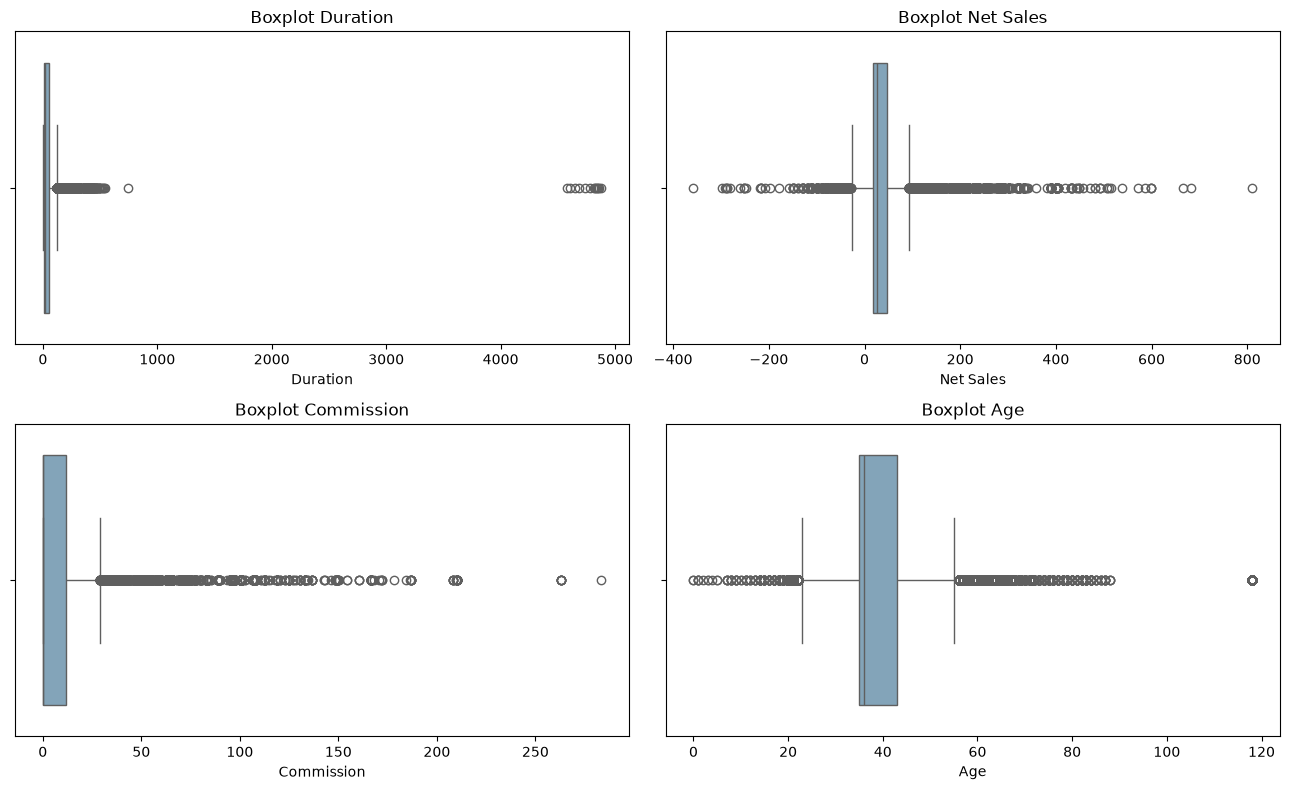

In [12]:
num_check = ["Duration", "Net Sales", "Commission", "Age"]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), num_check):
    sns.boxplot(x=df[col], ax=ax, color="#7aa6c2")
    ax.set_title(f"Boxplot {col}")
plt.tight_layout()
plt.show()

In [13]:
# Ringkasan nilai ekstrem sebagai bahan review boxplot
print("Duration < 0              :", (df["Duration"] < 0).sum())
print("Duration > 761 (1 tahun)  :", (df["Duration"] > 761).sum())
print("Duration 366-731          :", df["Duration"].between(366, 731).sum())
print("Age > 100                 :", (df["Age"] > 100).sum())
print("Age == 0                  :", (df["Age"] == 0).sum())
print("Net Sales < 0 (refund?)   :", (df["Net Sales"] < 0).sum())
print("Net Sales > 500           :", (df["Net Sales"] > 500).sum())
print()
print("Nilai Age tertinggi        :", sorted(df["Age"].unique())[-6:])
print("Duration > 761 per agensi/produk:")
display(df[df["Duration"] > 761].groupby(["Agency", "Product Name"]).size().rename("n"))
print("Age > 100 per agensi:")
display(df[df["Age"] > 100].groupby("Agency").size().rename("n"))
print("Claim pada baris Age > 100:", df.loc[df["Age"] > 100, "target"].sum())
print("Claim pada baris Duration > 761:", df.loc[df["Duration"] > 761, "target"].sum())

Duration < 0              : 2
Duration > 761 (1 tahun)  : 13
Duration 366-731          : 904
Age > 100                 : 676
Age == 0                  : 2
Net Sales < 0 (refund?)   : 483
Net Sales > 500           : 13

Nilai Age tertinggi        : [np.int64(84), np.int64(85), np.int64(86), np.int64(87), np.int64(88), np.int64(118)]
Duration > 761 per agensi/produk:


Agency  Product Name    
SSI     Ticket Protector    13
Name: n, dtype: int64

Age > 100 per agensi:


Agency
ADM      1
ART     36
CCR     28
CWT      1
EPX     29
JWT    522
JZI     49
SSI     10
Name: n, dtype: int64

Claim pada baris Age > 100: 7
Claim pada baris Duration > 761: 0


**Review Boxplot**
- **Duration**: sebaran utama berada di bawah ±550 hari, lalu ada kelompok terpisah jauh di **±4.600-4.900 hari (±13 tahun)** dan satu titik ±740 hari. Durasi sepanjang itu tidak masuk akal untuk polis perjalanan. Ada 14 baris Duration > 731 hari (13 di antaranya SSI *Ticket Protector*, 1 C2B *Annual Silver*, **0 klaim**) dan 2 baris Duration negatif. Baris dengan durasi 366-731 hari (904 baris) dipertahankan karena wajar untuk produk tahunan.
- **Age**: sebaran 0-88 tahun, lalu satu kelompok terpisah di **118 tahun (676 baris)**. Usia 118 tidak realistis dan terlihat seperti kode placeholder.
- **Net Sales**: berekor panjang ke kedua sisi (min -357,5, max 810) tetapi kontinu, tanpa lompatan terisolasi. Nilai negatif (483 baris) kemungkinan refund/pembatalan, dan polis premi tinggi wajar untuk produk tahunan. **Tidak di-drop**; ekstremnya ditangani Winsorizer di pipeline.
- **Commission**: berekor panjang tetapi kontinu (max 283,5) dan mayoritas bernilai 0. **Tidak di-drop**.

**Keputusan drop**: `Duration` < 0 atau > 731 hari, dan `Age` > 100. Total **690 baris** dibuang (7 di antaranya klaim, 677 menjadi 670).

> **Peringatan:** seluruh **522 baris agensi JWT** memiliki Age = 118, sehingga drop `Age` > 100 menghilangkan agensi JWT dari data. Model tidak pernah melihat JWT, dan polis JWT di produksi akan diperlakukan sebagai kategori tak dikenal. Alternatifnya (di luar instruksi) adalah mempertahankan baris tersebut dan menjadikan Age = 118 sebagai NaN yang diimputasi.

In [14]:
n_before = len(df)

# Drop policy dengan Duration tidak masuk akal (negatif, atau > 761 hari / > 2 tahun)
df = df[(df["Duration"] >= 0) & (df["Duration"] <= 761)]

# Drop policy dengan Age tidak masuk akal (> 100 tahun)
df = df[df["Age"] <= 100]

df = df.reset_index(drop=True)
print(f"Baris sebelum: {n_before} | sesudah: {len(df)} | dibuang: {n_before - len(df)}")
print("Distribusi target setelah drop:")
print(df["target"].value_counts())

Baris sebelum: 44328 | sesudah: 43639 | dibuang: 689
Distribusi target setelah drop:
target
0    42969
1      670
Name: count, dtype: int64


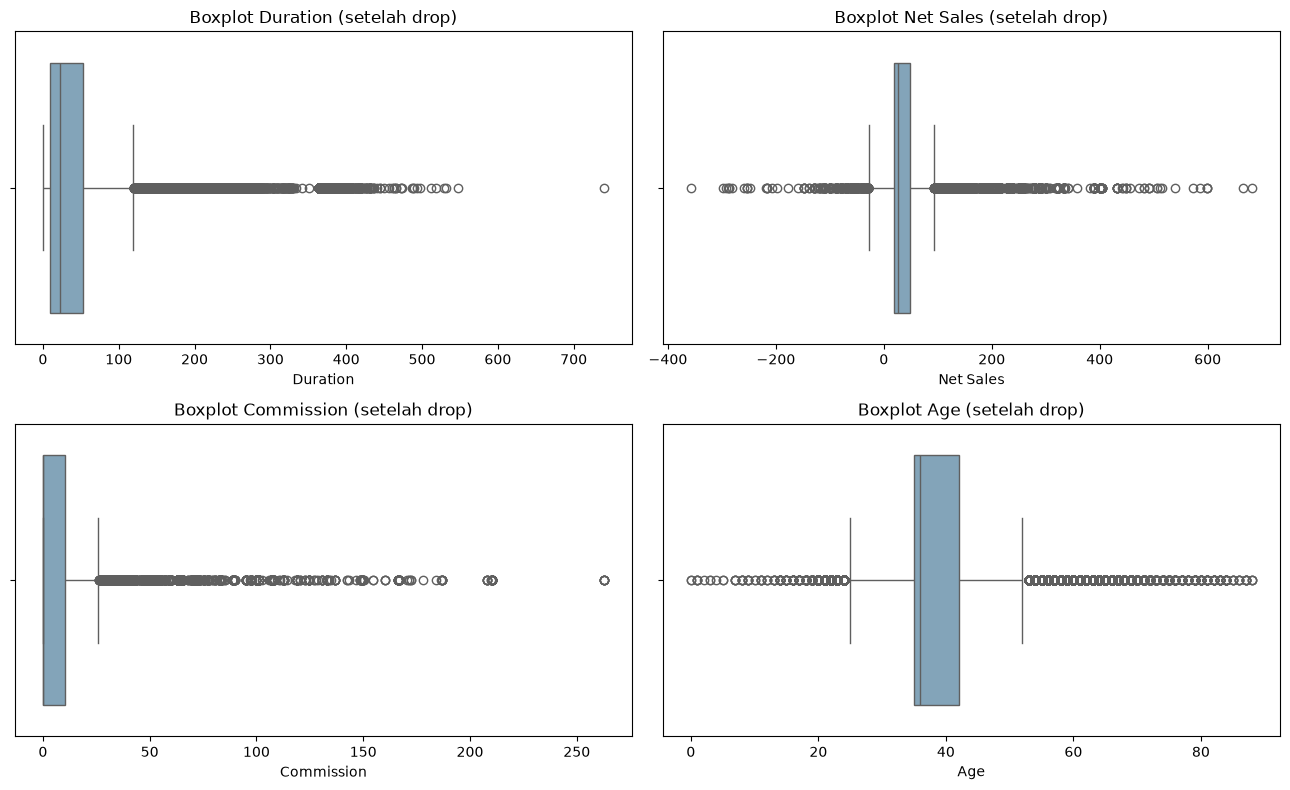

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col in zip(axes.ravel(), num_check):
    sns.boxplot(x=df[col], ax=ax, color="#7aa6c2")
    ax.set_title(f"Boxplot {col} (setelah drop)")
plt.tight_layout()
plt.show()

### *2.5 Drop Irrelevant Feature*

In [16]:
df = df.drop(columns="Gender")
df.columns.tolist()

['Agency',
 'Agency Type',
 'Distribution Channel',
 'Product Name',
 'Duration',
 'Destination',
 'Net Sales',
 'Commission',
 'Age',
 'target']

### *2.6 Define Feature and Target*

In [17]:
x = df.drop(columns="target")
y = df["target"]

print("x:", x.shape, "| y:", y.shape)

x: (43639, 9) | y: (43639,)


## **3. Exploratory Data Analysis & Feature Simplification**

### *3.1 Split Data into Train and Test Set*

> Split dilakukan **sebelum** analisis korelasi dan multikolinearitas. Keputusan membuang fitur memakai informasi target, sehingga jika dilakukan pada seluruh data, test set ikut "mengintip" proses seleksi fitur (*data leakage*) dan skor test menjadi terlalu optimistis. Semua analisis di Section 3 hanya memakai **data train**.

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42, stratify=y)
# reset index
x_train.reset_index(drop=True, inplace=True)
x_test.reset_index(drop=True, inplace=True)
y_train.reset_index(drop=True, inplace=True)
y_test.reset_index(drop=True, inplace=True)
# overview
print("Feature shape (train): ", x_train.shape)
print("Target shape (train): ", y_train.shape)
print("Feature shape (test): ", x_test.shape)
print("Claim rate train: {:.4f} | test: {:.4f}".format(y_train.mean(), y_test.mean()))
print("Jumlah klaim train:", y_train.sum(), "| test:", y_test.sum())

# gabungan fitur + target (train saja) untuk keperluan analisis
train_df = pd.concat([x_train, y_train], axis=1)

# salinan fitur lengkap, untuk membandingkan sebelum vs sesudah simplifikasi fitur
x_train_full, x_test_full = x_train.copy(), x_test.copy()

Feature shape (train):  (34911, 9)
Target shape (train):  (34911,)
Feature shape (test):  (8728, 9)
Claim rate train: 0.0154 | test: 0.0154
Jumlah klaim train: 536 | test: 134


### *3.2 Exploratory Data Analysis*

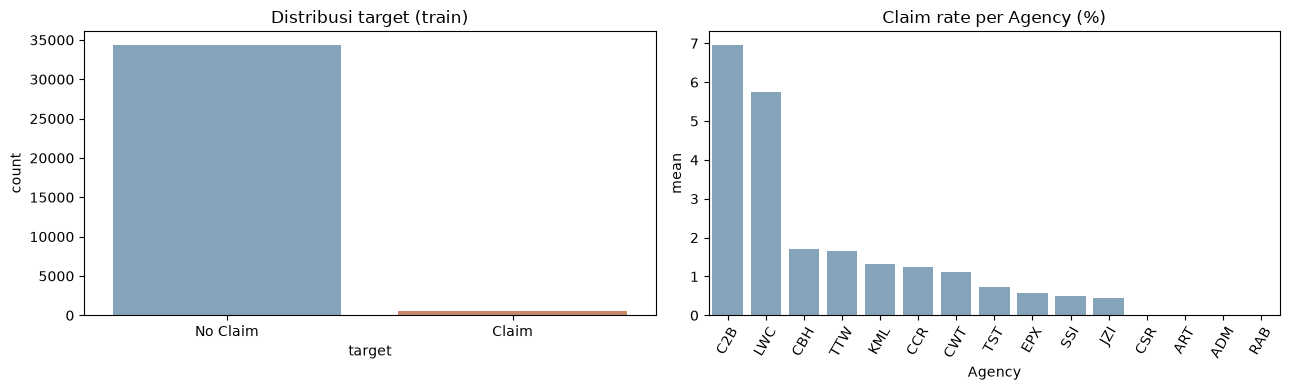

,claim_rate,n_rows,n_claim
Agency,,,
C2B,0.0696,4583,319
LWC,0.0575,365,21
CBH,0.0169,59,1
TTW,0.0167,60,1
KML,0.0133,226,3
CCR,0.0125,80,1
CWT,0.0112,4814,54
TST,0.0073,274,2
EPX,0.0058,19676,115


In [19]:
num_check = ["Duration", "Net Sales", "Commission", "Age"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x=y_train.map({0: "No Claim", 1: "Claim"}), ax=axes[0], palette=["#7aa6c2", "#d9825b"])
axes[0].set_title("Distribusi target (train)")
rate_agency = train_df.groupby("Agency")["target"].agg(["mean", "size"]).sort_values("mean", ascending=False)
sns.barplot(x=rate_agency.index, y=rate_agency["mean"] * 100, ax=axes[1], color="#7aa6c2")
axes[1].set_title("Claim rate per Agency (%)")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()
rate_agency.rename(columns={"mean": "claim_rate", "size": "n_rows"}).assign(n_claim=lambda t: (t["claim_rate"] * t["n_rows"]).round().astype(int)).round(4)

In [20]:
rate_product = (train_df.groupby("Product Name")["target"].agg(["mean", "sum", "size"])
                  .rename(columns={"mean": "claim_rate", "sum": "n_claim", "size": "n_rows"})
                  .sort_values("claim_rate", ascending=False))
rate_product.round(4)

,claim_rate,n_claim,n_rows
Product Name,,,
Annual Gold Plan,0.1182,13,110
Annual Silver Plan,0.1113,86,773
Annual Travel Protect Gold,0.0943,5,53
Spouse or Parents Comprehensive Plan,0.0909,1,11
Single Trip Travel Protect Platinum,0.0909,3,33
Annual Travel Protect Platinum,0.0800,2,25
Silver Plan,0.0683,85,1245
Annual Travel Protect Silver,0.0682,3,44
Gold Plan,0.0561,11,196


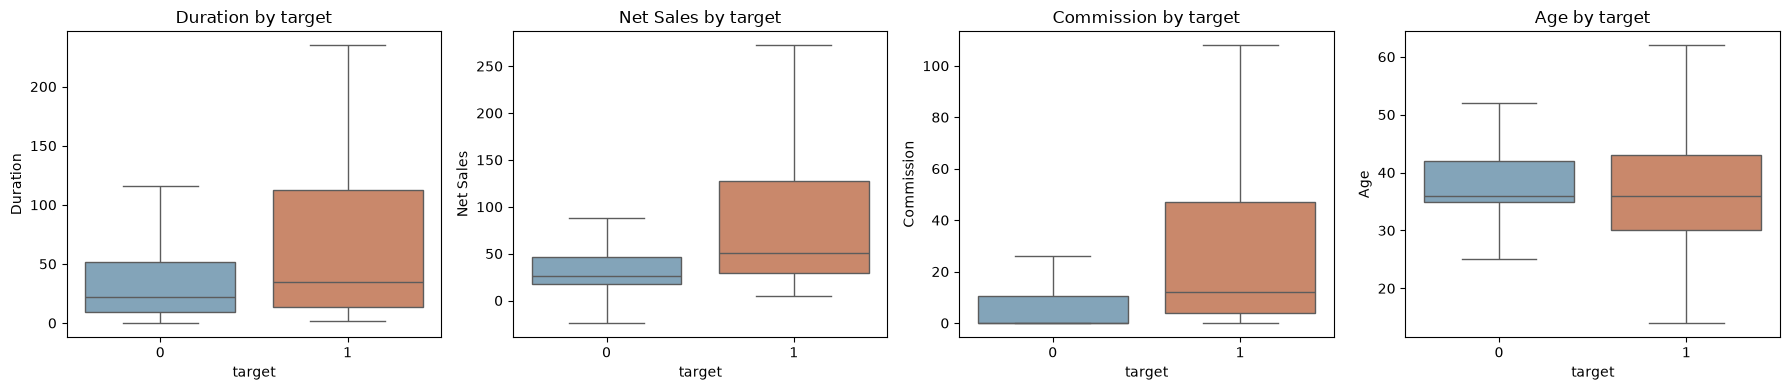

,Duration,Net Sales,Commission,Age
target,,,,
0,22.0,26.0,0.00,36.0
1,35.0,51.0,12.13,36.0


In [21]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, num_check):
    sns.boxplot(data=train_df, x="target", y=col, ax=ax, palette=["#7aa6c2", "#d9825b"], showfliers=False)
    ax.set_title(f"{col} by target")
plt.tight_layout()
plt.show()

train_df.groupby("target")[num_check].median()

**Ringkasan EDA** (data train)
- Target sangat timpang: klaim hanya **1,54%** (536 dari 34.910 polis). Accuracy tidak informatif, sehingga evaluasi memakai **PR-AUC**, **Recall**, **F2**, dan **cost-benefit**. Baseline PR-AUC acak = prevalensi (±0,015).
- **Agensi adalah pembeda terkuat**: C2B claim rate 6,94% (319 dari 536 klaim, ±60%) dan LWC 5,68%, sedangkan EPX hanya 0,58% dan JZI 0,45%. Risiko sangat terkonsentrasi pada satu agensi. Agensi kecil (TTW, CBH, KML, CCR) memiliki 1-3 klaim sehingga claim rate-nya tidak stabil.
- **Produk tahunan** punya claim rate tinggi (Annual Gold Plan 12,6%, Annual Silver Plan 11,0%, Annual Travel Protect Gold 10,6%), jauh di atas *Cancellation Plan* (0,29%). Beberapa produk hanya berisi puluhan baris, sehingga angkanya perlu dibaca hati-hati.
- Pada polis yang klaim, nilai tengah **Net Sales (51 vs 26)**, **Duration (35 vs 22 hari)**, dan **Commission (12,1 vs 0)** lebih tinggi. **Age** hampir tidak berbeda (median sama-sama 36).
- Semua pernyataan di atas bersifat asosiasi, bukan sebab-akibat.

### *3.3 Korelasi Feature dengan Target*

Setiap fitur diuji apakah berasosiasi signifikan dengan `target` (data train):
- **Fitur numerik**: uji Mann-Whitney U (membandingkan sebaran fitur pada kelompok klaim vs tidak klaim, tanpa asumsi normal) dan korelasi Spearman.
- **Fitur kategorikal**: uji asosiasi chi-square (statistik) dengan **p-value permutasi** (2.000 kali acak target). Pendekatan permutasi dipakai karena kelas klaim sangat sedikit, sehingga banyak sel kontingensi berisi < 5 data dan p-value chi-square klasik kurang andal (terutama `Destination` dengan 138 kategori). Ukuran efek: Cramér's V.
- **Aturan keputusan**: fitur dengan p-value ≥ 0,05 dianggap tidak signifikan dan di-drop.

> Keterbatasan: uji univariat tidak menangkap interaksi antar fitur, dan pada data besar efek yang sangat kecil pun bisa signifikan. Karena itu ukuran efek ikut ditampilkan.

In [22]:
from scipy import stats

ALPHA = 0.05
N_PERM = 2000

def perm_chi2_test(cat_series, y, n_perm=N_PERM, seed=42):
    # chi-square statistic + permutation p-value (kategori vs target biner)
    codes, _ = pd.factorize(cat_series)
    k = codes.max() + 1
    y_arr = np.asarray(y)
    def chi2_stat(yv):
        ct = np.bincount(codes * 2 + yv, minlength=2 * k).reshape(k, 2).astype(float)
        exp = ct.sum(1, keepdims=True) * ct.sum(0, keepdims=True) / ct.sum()
        return ((ct - exp) ** 2 / np.where(exp == 0, 1, exp)).sum(), (exp < 5).mean()
    obs, low_exp = chi2_stat(y_arr)
    rng = np.random.default_rng(seed)
    perm = np.array([chi2_stat(rng.permutation(y_arr))[0] for _ in range(n_perm)])
    p_perm = (1 + (perm >= obs).sum()) / (n_perm + 1)
    n = len(y_arr)
    cramers_v = np.sqrt(obs / (n * (min(k, 2) - 1)))
    return obs, p_perm, cramers_v, low_exp

cat_features = ["Agency", "Agency Type", "Distribution Channel", "Product Name", "Destination"]
num_features = ["Duration", "Net Sales", "Commission", "Age"]

rows = []
for c in cat_features:
    chi2_obs, p_perm, v, low_exp = perm_chi2_test(x_train[c], y_train)
    chi2_p = stats.chi2_contingency(pd.crosstab(x_train[c], y_train))[1]
    rows.append({"feature": c, "type": "kategorikal", "test": "chi-square (permutasi)",
                 "statistic": chi2_obs, "effect_size": v, "p_value": p_perm, "p_value_chi2_klasik": chi2_p,
                 "sel_kontingensi_exp<5 (%)": low_exp * 100})
for c in num_features:
    u, p_u = stats.mannwhitneyu(x_train.loc[y_train == 1, c], x_train.loc[y_train == 0, c])
    rho, p_rho = stats.spearmanr(x_train[c], y_train)
    rows.append({"feature": c, "type": "numerik", "test": "Mann-Whitney U",
                 "statistic": u, "effect_size": abs(rho), "p_value": p_u, "p_value_chi2_klasik": np.nan,
                 "sel_kontingensi_exp<5 (%)": np.nan, "spearman_rho": rho, "p_spearman": p_rho})

corr_target = pd.DataFrame(rows)
corr_target["p_bonferroni"] = (corr_target["p_value"] * len(corr_target)).clip(upper=1)
corr_target["significant"] = corr_target["p_value"] < ALPHA
corr_target = corr_target.sort_values("p_value").reset_index(drop=True)
corr_target

,feature,type,test,statistic,effect_size,p_value,p_value_chi2_klasik,sel_kontingensi_exp<5 (%),spearman_rho,p_spearman,p_bonferroni,significant
0,Commission,numerik,Mann-Whitney U,1.310813e+07,0.099493,3.909887e-77,NaN,NaN,0.099493,1.661308e-77,3.518898e-76,True
1,Net Sales,numerik,Mann-Whitney U,1.329680e+07,0.094487,9.438455e-70,NaN,NaN,0.094487,4.708931e-70,8.494610e-69,True
2,Duration,numerik,Mann-Whitney U,1.139326e+07,0.050421,4.479845e-21,NaN,NaN,0.050421,4.239194e-21,4.031860e-20,True
3,Age,numerik,Mann-Whitney U,8.061462e+06,0.027435,2.959149e-07,NaN,NaN,-0.027435,2.945715e-07,2.663234e-06,True
4,Agency Type,kategorikal,chi-square (permutasi),3.721602e+02,0.103249,4.997501e-04,1.641944e-82,0.000000,NaN,NaN,4.497751e-03,True
5,Product Name,kategorikal,chi-square (permutasi),1.278722e+03,0.191385,4.997501e-04,2.929398e-254,32.692308,NaN,NaN,4.497751e-03,True
6,Destination,kategorikal,chi-square (permutasi),5.952177e+02,0.130574,4.997501e-04,1.137829e-59,63.805970,NaN,NaN,4.497751e-03,True
7,Agency,kategorikal,chi-square (permutasi),1.101301e+03,0.177612,4.997501e-04,2.806905e-226,26.666667,NaN,NaN,4.497751e-03,True
8,Distribution Channel,kategorikal,chi-square (permutasi),2.258536e-01,0.002544,7.226387e-01,7.645485e-01,0.000000,NaN,NaN,1.000000e+00,False


In [23]:
cols_drop_insignificant = corr_target.loc[~corr_target["significant"], "feature"].tolist()
print("Fitur tidak signifikan terhadap target (p >= %.2f) -> di-drop:" % ALPHA, cols_drop_insignificant)

Fitur tidak signifikan terhadap target (p >= 0.05) -> di-drop: ['Distribution Channel']


**Analisis Korelasi Feature dengan Target**
- **Signifikan (p < 0,05) dan dipertahankan**: Commission (Spearman ρ = 0,099), Net Sales (0,094), Duration (0,050), Age (-0,027), serta Agency (Cramér's V 0,177), Product Name (0,191), Destination (0,130), dan Agency Type (0,103). Untuk fitur kategorikal, p-value permutasi 0,0005 adalah batas terkecil yang bisa dicapai dengan 2.000 permutasi, artinya tidak ada permutasi acak yang melampaui statistik asli.
- **Tidak signifikan dan di-drop: `Distribution Channel`** (V = 0,003; p = 0,73; p chi-square klasik 0,75). Ini konsisten dengan dominasi Online (98,3%): hampir semua polis ada di satu kategori sehingga tidak membawa informasi tentang klaim.
- Koreksi Bonferroni (9 uji) tidak mengubah keputusan: semua fitur yang signifikan tetap signifikan, dan Distribution Channel tetap tidak signifikan.
- **Signifikan bukan berarti kuat.** Dengan 34.910 baris, efek yang sangat kecil pun lolos uji. Korelasi numerik semuanya lemah (|ρ| ≤ 0,10), dan Age (|ρ| = 0,027) paling lemah. Mengikuti aturan yang diminta (drop jika tidak signifikan), Age dan Duration tetap dipertahankan; jika ingin simplifikasi lebih agresif, kandidat berikutnya adalah Age lalu Duration (**perlu verifikasi** lewat ablasi performa).
- `Destination`: ±63% sel kontingensi memiliki frekuensi harapan < 5, sehingga p-value chi-square klasik kurang andal. Uji permutasi tetap menunjukkan asosiasi signifikan.
- Keterbatasan: uji univariat tidak menangkap interaksi, sehingga fitur yang lemah sendirian tetapi berguna dalam kombinasi bisa tersingkir.

### *3.4 Analisis Multikolinearitas antar Feature*

- **Kategorikal vs kategorikal**: Cramér's V terkoreksi bias (0 = tidak ada asosiasi, 1 = saling menentukan sepenuhnya).
- **Numerik vs numerik**: korelasi Spearman dan *Variance Inflation Factor* (VIF; VIF > 5 umumnya dianggap perlu dicermati).
- **Aturan keputusan**: pasangan kategorikal dengan Cramér's V ≥ 0,90 dianggap redundan; kolom dengan jumlah kategori **lebih sedikit** (informasi lebih kasar) di-drop dan yang lebih rinci dipertahankan.
- Analisis dilakukan pada fitur yang lolos uji signifikansi (3.3).

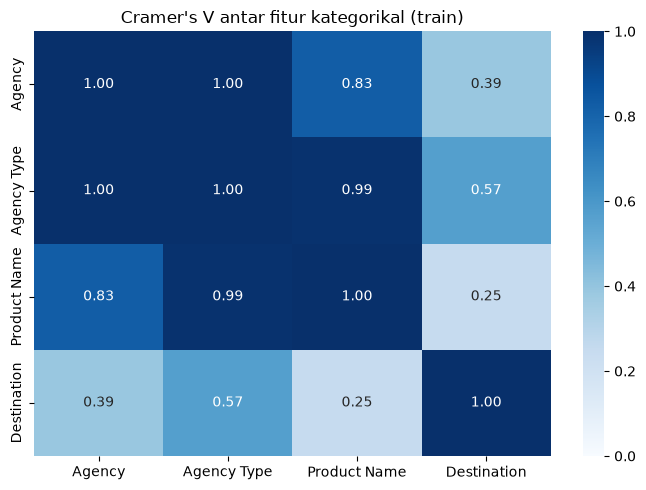

,Agency,Agency Type,Product Name,Destination
Agency,1.000,1.000,0.828,0.389
Agency Type,1.000,1.000,0.989,0.569
Product Name,0.828,0.989,1.000,0.251
Destination,0.389,0.569,0.251,1.000


In [24]:
def cramers_v_corrected(a, b):
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))

cat_remaining = [c for c in cat_features if c not in cols_drop_insignificant]
num_remaining = [c for c in num_features if c not in cols_drop_insignificant]

cv_matrix = pd.DataFrame(np.eye(len(cat_remaining)), index=cat_remaining, columns=cat_remaining)
for i, a in enumerate(cat_remaining):
    for b in cat_remaining[i + 1:]:
        cv_matrix.loc[a, b] = cv_matrix.loc[b, a] = cramers_v_corrected(x_train[a], x_train[b])

plt.figure(figsize=(7, 5))
sns.heatmap(cv_matrix.astype(float), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Cramer's V antar fitur kategorikal (train)")
plt.tight_layout()
plt.show()
cv_matrix.round(3)

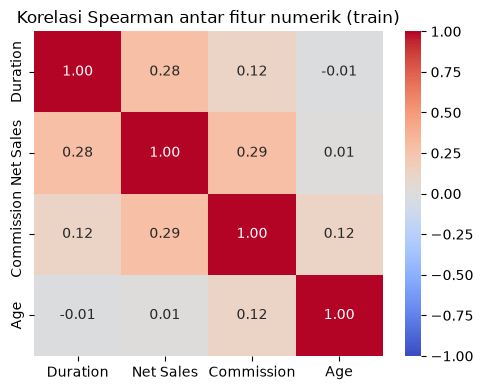

,VIF
Duration,1.601
Net Sales,2.112
Commission,1.774
Age,1.014


In [25]:
# Numerik: korelasi Spearman + VIF
spearman_matrix = x_train[num_remaining].corr(method="spearman")
plt.figure(figsize=(5, 4))
sns.heatmap(spearman_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Korelasi Spearman antar fitur numerik (train)")
plt.tight_layout()
plt.show()

from sklearn.linear_model import LinearRegression
Z = (x_train[num_remaining] - x_train[num_remaining].mean()) / x_train[num_remaining].std()
vif = {}
for c in num_remaining:
    others = [o for o in num_remaining if o != c]
    r2 = LinearRegression().fit(Z[others], Z[c]).score(Z[others], Z[c]) if others else 0
    vif[c] = 1 / (1 - r2)
pd.Series(vif, name="VIF").round(3).to_frame()

In [26]:
# Aturan: pasangan kategorikal dengan Cramer's V >= 0.90 -> drop kolom dengan kategori lebih sedikit
V_THRESHOLD = 0.90
cols_drop_collinear = []
for i, a in enumerate(cat_remaining):
    for b in cat_remaining[i + 1:]:
        if cv_matrix.loc[a, b] >= V_THRESHOLD:
            drop = a if x_train[a].nunique() < x_train[b].nunique() else b
            keep = b if drop == a else a
            print(f"{a} <-> {b}: V = {cv_matrix.loc[a, b]:.3f} -> drop '{drop}' (kategori lebih kasar), pertahankan '{keep}'")
            if drop not in cols_drop_collinear:
                cols_drop_collinear.append(drop)
print("Kolom redundan yang di-drop:", cols_drop_collinear)

Agency <-> Agency Type: V = 1.000 -> drop 'Agency Type' (kategori lebih kasar), pertahankan 'Agency'
Agency Type <-> Product Name: V = 0.989 -> drop 'Agency Type' (kategori lebih kasar), pertahankan 'Product Name'
Kolom redundan yang di-drop: ['Agency Type']


**Analisis Multikolinearitas**
- **Agency <-> Agency Type: Cramér's V = 1,000.** Setiap agensi hanya punya satu tipe, sehingga `Agency Type` adalah fungsi dari `Agency`. Asosiasinya dengan `Product Name` juga hampir penuh (V = 0,989). `Agency Type` tidak membawa informasi baru dan **di-drop**; `Agency` (16 kategori, lebih rinci) dipertahankan.
- **Agency <-> Product Name: V = 0,827.** Tinggi, tetapi di bawah ambang 0,90: produk bersarang di agensi, tetapi keduanya masih membawa informasi berbeda (sebuah agensi menjual beberapa produk). Keduanya dipertahankan. Konsekuensinya, koefisien/SHAP `Agency` dan `Product Name` tidak boleh dibaca sebagai efek yang benar-benar independen.
- Asosiasi `Destination` dengan fitur lain sedang-rendah (V 0,25-0,57), bukan redundansi.
- **Numerik: tidak ada multikolinearitas yang bermasalah.** VIF Duration 1,61; Net Sales 2,10; Commission 1,77; Age 1,02, semuanya jauh di bawah 5. Net Sales dan Commission berasosiasi paling kuat tetapi masih wajar.
- **Keputusan: drop `Agency Type`.**

### *3.5 Final Feature Set*

In [27]:
cols_to_drop = list(dict.fromkeys(cols_drop_insignificant+cols_drop_collinear))
print("Kolom yang di-drop:", cols_to_drop)

x = x.drop(columns=cols_to_drop)
x_train = x_train.drop(columns=cols_to_drop)
x_test = x_test.drop(columns=cols_to_drop)

print("Fitur sebelum simplifikasi:", x_train_full.shape[1], "| sesudah:", x_train.shape[1])
print("Fitur final:", x_train.columns.tolist())

# simpan data bersih (fitur final + target), dipakai pada tahap deployment
pd.concat([x, y], axis=1).to_csv("data_clean.csv", index=False)

Kolom yang di-drop: ['Distribution Channel', 'Agency Type']
Fitur sebelum simplifikasi: 9 | sesudah: 7
Fitur final: ['Agency', 'Product Name', 'Duration', 'Destination', 'Net Sales', 'Commission', 'Age']


**Ringkasan Final Feature Set**
- Fitur berkurang dari **9 menjadi 7**. Dibuang: `Distribution Channel` (tidak signifikan terhadap target) dan `Agency Type` (redundan dengan `Agency`).
- Fitur final: `Agency`, `Product Name`, `Destination`, `Duration`, `Net Sales`, `Commission`, `Age`.
- Simplifikasi ini **ringan**: kedua kolom yang dibuang memang tidak membawa informasi unik. Dampaknya terhadap overfitting dievaluasi di Section 5.5.
- `data_clean.csv` disimpan dengan fitur final + target.

## **4. Feature Engineering**

### *4.1 Create Feature Engineering Pipeline*

In [28]:
# Pipeline - Kategorikal Nominal (cardinality rendah)
nominal_pipeline = Pipeline(steps=[
    ("feature_imputation", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("feature_encoding", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"))
])

# Pipeline - Kategorikal cardinality tinggi (Destination, 138 kategori) -> Target Encoding
# TargetEncoder sklearn memakai cross-fitting internal sehingga tidak bocor ke target pada fold yang sama
destination_pipeline = Pipeline(steps=[
    ("feature_imputation", SimpleImputer(strategy="constant", fill_value="unknown")),
    ("feature_encoding", TargetEncoder(target_type="binary", random_state=42))
])

# Pipeline - Numerical
numerical_pipeline = Pipeline(steps=[
    ("feature_imputation", SimpleImputer(strategy="median")),
    ("outlier_handling", Winsorizer(capping_method="iqr", fold=3)),
    ("feature_scaling", StandardScaler())
])

### *4.2 Transform Feature*

In [29]:
def build_preprocessing(columns):
    # susun ColumnTransformer hanya dari kolom yang tersedia (setelah simplifikasi fitur)
    nominal = [c for c in ["Agency", "Agency Type", "Distribution Channel", "Product Name"] if c in columns]
    destination = [c for c in ["Destination"] if c in columns]
    numerical = [c for c in ["Duration", "Net Sales", "Commission", "Age"] if c in columns]
    transformers = []
    if nominal:
        transformers.append(("categorical_nominal", nominal_pipeline, nominal))
    if destination:
        transformers.append(("categorical_destination", destination_pipeline, destination))
    if numerical:
        transformers.append(("numerical", numerical_pipeline, numerical))
    return ColumnTransformer(transformers=transformers, remainder="drop", verbose_feature_names_out=False)

# Create feature transformation object (fitur final)
preprocessing = build_preprocessing(x_train.columns)
# versi fitur lengkap, hanya untuk perbandingan efek simplifikasi (Section 5.5)
preprocessing_full = build_preprocessing(x_train_full.columns)
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_nominal', ...), ('categorical_destination', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative 

### *4.3 Feature Engineering Overview*

In [30]:
# Fiting to Data Train
preprocessing.set_output(transform='pandas')
preprocessing.fit(x_train, y_train)
# Transform train and test set
x_train_pre = preprocessing.transform(x_train)
x_test_pre = preprocessing.transform(x_test)
print("Shape setelah preprocessing:", x_train_pre.shape, x_test_pre.shape)
print("Missing value setelah preprocessing:", x_train_pre.isnull().sum().sum())
display(x_train_pre.head())
x_train_pre.columns

Shape setelah preprocessing: (34911, 44) (8728, 44)
Missing value setelah preprocessing: 0


,Agency_ART,Agency_C2B,Agency_CBH,Agency_CCR,Agency_CSR,Agency_CWT,Agency_EPX,Agency_JZI,Agency_KML,Agency_LWC,Agency_RAB,Agency_SSI,Agency_TST,Agency_TTW,Product Name_2 way Comprehensive Plan,Product Name_24 Protect,Product Name_Annual Gold Plan,Product Name_Annual Silver Plan,Product Name_Annual Travel Protect Gold,Product Name_Annual Travel Protect Platinum,Product Name_Annual Travel Protect Silver,Product Name_Basic Plan,Product Name_Bronze Plan,Product Name_Cancellation Plan,Product Name_Child Comprehensive Plan,Product Name_Comprehensive Plan,Product Name_Gold Plan,Product Name_Individual Comprehensive Plan,Product Name_Premier Plan,Product Name_Rental Vehicle Excess Insurance,Product Name_Silver Plan,Product Name_Single Trip Travel Protect Gold,Product Name_Single Trip Travel Protect Platinum,Product Name_Single Trip Travel Protect Silver,Product Name_Spouse or Parents Comprehensive Plan,Product Name_Ticket Protector,Product Name_Travel Cruise Protect,Product Name_Travel Cruise Protect Family,Product Name_Value Plan,Destination,Duration,Net Sales,Commission,Age
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.009295,-0.760666,-0.795204,-0.619971,-0.687838
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.008363,-0.300805,0.011845,-0.619971,-0.264666
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.044424,-0.196291,-0.391680,-0.155459,0.052713
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.044424,-0.635249,0.207629,0.240324,-0.687838
4,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.009295,-0.363513,-0.496297,-0.619971,-1.111010


Index(['Agency_ART', 'Agency_C2B', 'Agency_CBH', 'Agency_CCR', 'Agency_CSR',
       'Agency_CWT', 'Agency_EPX', 'Agency_JZI', 'Agency_KML', 'Agency_LWC',
       'Agency_RAB', 'Agency_SSI', 'Agency_TST', 'Agency_TTW',
       'Product Name_2 way Comprehensive Plan', 'Product Name_24 Protect',
       'Product Name_Annual Gold Plan', 'Product Name_Annual Silver Plan',
       'Product Name_Annual Travel Protect Gold',
       'Product Name_Annual Travel Protect Platinum',
       'Product Name_Annual Travel Protect Silver', 'Product Name_Basic Plan',
       'Product Name_Bronze Plan', 'Product Name_Cancellation Plan',
       'Product Name_Child Comprehensive Plan',
       'Product Name_Comprehensive Plan', 'Product Name_Gold Plan',
       'Product Name_Individual Comprehensive Plan',
       'Product Name_Premier Plan',
       'Product Name_Rental Vehicle Excess Insurance',
       'Product Name_Silver Plan',
       'Product Name_Single Trip Travel Protect Gold',
       'Product Name_Single Tri

## **5. Modeling**

### *5.0 Metric Evaluation*

Metrik yang dipakai pada seleksi model, tuning, dan resampling (semua dihitung pada validation fold):

| Metrik | Cara hitung | Peran |
|---|---|---|
| **PR-AUC** | area di bawah kurva Precision-Recall dari `predict_proba`, dengan integrasi bertingkat (*step-wise*, tanpa interpolasi linear) | ukuran ranking tanpa threshold |
| **Recall** | TP / (TP + FN) pada threshold 0,5 | seberapa banyak polis klaim yang tertangkap |
| **F2** | F-beta dengan beta = 2 pada threshold 0,5 (recall dibobot lebih besar dari precision) | keseimbangan precision-recall yang condong ke recall |
| **Cost-benefit** | penghematan (Rp miliar) = TP x COST_FN - FP x COST_FP, dibanding tanpa model | dampak finansial |

> **Mengapa PR-AUC *step-wise*, bukan trapesium?** Integrasi trapesium (`auc(recall, precision)`) menginterpolasi linear antar titik kurva PR, dan itu terlalu optimistis ketika model hanya punya sedikit nilai probabilitas yang berbeda. Terbukti di data ini: untuk `DummyClassifier` (probabilitas konstan) hasilnya sekitar **0,51** padahal prevalensi klaim hanya **0,015**. Karena itu ranking model memakai integrasi bertingkat. Hati-hati: rumus ini sama dengan yang dihitung `average_precision_score` di scikit-learn, jadi secara numerik tetap "AP". Variabel `PR_AUC_METHOD` bisa diganti ke `"trapezoid"` untuk membandingkan.

`PRIMARY_METRIC` menentukan metrik yang dipakai untuk mengurutkan hasil benchmark dan memilih hyperparameter (`refit`) pada GridSearch. Metrik lain tetap dilaporkan sebagai pembanding.

In [ ]:
# Asumsi biaya (dipakai juga di Section 9): premi = rata-rata Net Sales (satuan USD),

avg_premium = df["Net Sales"].mean()
avg_commission = df["Commission"].mean()
avg_margin = avg_premium - avg_commission

COST_FP = avg_margin  # loss opportunity: keuntungan polis yang hilang (USD) = premi - comission
COST_FN = 2609                  # kerugian: sebesar rata2 claim travel insurance (asumsi, USD) ref:https://www.squaremouth.com/press-room/rising-travel-costs-led-to-a-big-shift-in-travel-insurance-payouts-in-2024
print(f"COST_FN: USD {COST_FN:,.2f} | COST_FP: USD {COST_FP:,.2f} | rasio FN:FP = {COST_FN/COST_FP:.2f}")

# --- custom scorer ---
PR_AUC_METHOD = "step"   # "step" (disarankan) atau "trapezoid"

def pr_auc_score(y_true, y_proba):
    precision, recall, _ = precision_recall_curve(y_true, y_proba)
    if PR_AUC_METHOD == "trapezoid":
        return auc(recall, precision)
    # integrasi bertingkat (tanpa interpolasi linear): sum((R_n - R_{n-1}) * P_n)
    return -np.sum(np.diff(recall) * precision[:-1])

def savings_usd(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tp * COST_FN - fp * COST_FP     # USD vs tanpa model

scorers = {
    "pr_auc": make_scorer(pr_auc_score, response_method="predict_proba"),
    "recall": make_scorer(recall_score, zero_division=0),
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "savings": make_scorer(savings_usd),
}
PRIMARY_METRIC = "pr_auc"    # metrik utama untuk ranking model & refit GridSearch

def summarize_cv(cv_out, label_col, label):
    row = {label_col: label}
    for m in scorers:
        row[f"{m}_train"] = np.mean(cv_out[f"train_{m}"])
        row[f"{m}_test"] = np.mean(cv_out[f"test_{m}"])
        row[f"{m}_std"] = np.std(cv_out[f"test_{m}"])
    row["gap_score"] = row[f"{PRIMARY_METRIC}_train"] - row[f"{PRIMARY_METRIC}_test"]
    row["CV_test"] = row[f"{PRIMARY_METRIC}_std"] / row[f"{PRIMARY_METRIC}_test"] if row[f"{PRIMARY_METRIC}_test"] else np.nan
    return row

show_cols = ["recall_test", "f2_test", "savings_test", "pr_auc_train", "pr_auc_test", "pr_auc_std", "gap_score", "CV_test"]

COST_FN: USD 2,609.00 | COST_FP: USD 30.86 | rasio FN:FP = 84.55


### *5.1 Model Initialization*

In [32]:
# rasio negatif : positif, sesuai dokumentasi XGBoost scale_pos_weight = sum(negative) / sum(positive)
pos_weights = y_train.value_counts()[0] / y_train.value_counts()[1]
print("scale_pos_weight (neg/pos):", round(pos_weights, 2))

dummy = DummyClassifier(random_state=42)
logreg = LogisticRegression(random_state=42, max_iter=1000)
dtree = DecisionTreeClassifier(random_state=42)
knn = KNeighborsClassifier()
logreg_cw = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
dtree_cw = DecisionTreeClassifier(random_state=42, class_weight='balanced')

# Ensemble
rf = RandomForestClassifier(random_state=42)
rf_cw = RandomForestClassifier(random_state=42, class_weight='balanced')
xgb = XGBClassifier(random_state=42)
xgb_cw = XGBClassifier(scale_pos_weight=pos_weights, random_state=42)
gbs = GradientBoostingClassifier(random_state=42)
adaboost = AdaBoostClassifier(random_state=42)
lgbm = LGBMClassifier(random_state=42, n_jobs=1, verbose=-1)
lgbm_cw = LGBMClassifier(scale_pos_weight=pos_weights, random_state=42, n_jobs=1, verbose=-1)

model_dict = {
    "Dummy Classifier": dummy,
    "Logistic Regression": logreg,
    "Decision Tree Classifier": dtree,
    "K Neighbors Classifier": knn,
    "Random Forest Classifier": rf,
    "Logistic Regression using Classweight": logreg_cw,
    "Decision Tree Classifier using Class Weight": dtree_cw,
    "RandomForestClassifier using Class Weight": rf_cw,
    "XGboost Classifier": xgb,
    "XGBoost Classifier using Class Weight": xgb_cw,
    "Gradient Boosting Classifier": gbs,
    "Adaboost Classifier": adaboost,
    "LightGBM Classifier": lgbm,
    "LightGBM Classifier using Class Weight": lgbm_cw
}

scale_pos_weight (neg/pos): 64.13


### *5.2 Create Model Pipeline*

In [33]:
# Base classifier
base_classifier = Pipeline(steps=[
    ("feature_preprocessing", preprocessing),
    ("model", dummy)
])

# Classifier with feature selection
fs_classifier = Pipeline(steps=[
    ("feature_preprocessing", preprocessing),
    ("feature_selection",SelectFpr(alpha=0.1)),
    ("model", dummy)
])

### *5.3 Model Benchmarking*

In [34]:
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pipeline test using cross validation
trainingResult = cross_validate(base_classifier,X=x_train,y=y_train,
                                scoring=scorers, cv=skfold, return_train_score=True,
                                return_estimator=True)
pd.DataFrame({k: v for k, v in trainingResult.items() if k != "estimator"})

,fit_time,score_time,test_pr_auc,train_pr_auc,test_recall,train_recall,test_f2,train_f2,test_savings,train_savings
0,0.511366,0.304976,0.015466,0.015325,0.0,0.0,0.0,0.0,0.0,0.0
1,0.455067,0.251972,0.015325,0.015360,0.0,0.0,0.0,0.0,0.0,0.0
2,0.371083,0.199887,0.015325,0.015360,0.0,0.0,0.0,0.0,0.0,0.0
3,0.280144,0.173359,0.015325,0.015360,0.0,0.0,0.0,0.0,0.0,0.0
4,0.261622,0.153478,0.015325,0.015360,0.0,0.0,0.0,0.0,0.0,0.0


In [35]:
def run_benchmark(classifier, models, X, y, cv):
    result = []
    for model_name, clf in models.items():
        classifier.set_params(model=clf)
        crossval_score = cross_validate(classifier, X=X, y=y, cv=cv, scoring=scorers,
                                        return_train_score=True, n_jobs=-1)
        result.append(summarize_cv(crossval_score, "model_name", model_name))
    result_df = pd.DataFrame(result)
    return result_df.sort_values(f"{PRIMARY_METRIC}_test", ascending=False).reset_index(drop=True)

# Benchmarking process (Base classifier)
bench_base = run_benchmark(base_classifier, model_dict, x_train, y_train, skfold)
bench_base[["model_name"] + show_cols]

,model_name,recall_test,f2_test,savings_test,pr_auc_train,pr_auc_test,pr_auc_std,gap_score,CV_test
0,Logistic Regression,0.000000,0.000000,0.000000,0.080442,0.079851,0.014282,5.908646e-04,0.178853
1,Logistic Regression using Classweight,0.701506,0.202060,-9928.892144,0.079296,0.078636,0.014085,6.593188e-04,0.179117
2,Gradient Boosting Classifier,0.000000,0.000000,-15.297377,0.181260,0.074948,0.007637,1.063122e-01,0.101894
3,Adaboost Classifier,0.000000,0.000000,0.000000,0.072605,0.072237,0.007034,3.680496e-04,0.097374
4,LightGBM Classifier,0.001869,0.002331,-1.477192,0.412432,0.066626,0.013146,3.458063e-01,0.197306
5,XGBoost Classifier using Class Weight,0.345137,0.201502,-2854.712969,0.387848,0.065046,0.014165,3.228022e-01,0.217763
6,LightGBM Classifier using Class Weight,0.472066,0.208332,-5041.341852,0.242385,0.062704,0.011077,1.796813e-01,0.176656
7,XGboost Classifier,0.001869,0.002326,-22.511086,0.456940,0.057836,0.007647,3.991038e-01,0.132224
8,RandomForestClassifier using Class Weight,0.091433,0.092468,-466.289885,0.365713,0.051338,0.008841,3.143744e-01,0.172213
9,Random Forest Classifier,0.011198,0.013515,-96.823072,0.490316,0.044866,0.008277,4.454507e-01,0.184488


**Pemilihan Model Terbaik (tanpa Feature Selection, fitur final)**

Metrik: PR-AUC (utama, untuk ranking), Recall, F2 (threshold 0,5), dan Savings (cost-benefit, Rp miliar per validation fold).

- **Ranking PR-AUC**: Logistic Regression (**0,0794**), Gradient Boosting (0,0791), Logistic Regression + class weight (0,0777), AdaBoost (0,0717), LightGBM (0,0676), XGBoost + class weight (0,0661). Baseline Dummy = 0,0154. Tiga teratas **berbeda kurang dari 1 std CV** (±0,005-0,009), sehingga tidak bisa dibedakan secara statistik.
- **Model kompleks overfit berat**: gap train-validation Random Forest 0,49, XGBoost 0,39, LightGBM 0,33, XGBoost + class weight 0,31, sementara PR-AUC validasinya lebih rendah daripada model linear. Logistic Regression, Logistic Regression + class weight, dan AdaBoost hampir tanpa gap (<0,001). Gradient Boosting setara PR-AUC-nya dengan Logistic Regression tetapi gap-nya 0,097.
- **Recall dan F2 pada threshold 0,5 sangat bergantung pada class weight.** Tanpa class weight, hampir semua model nyaris tidak menandai polis klaim (recall ≈ 0). Dengan class weight: Logistic Regression recall 0,71 / F2 0,203, XGBoost 0,35 / 0,204, LightGBM 0,44 / 0,195. Nilai F2 hampir sama sehingga tidak membedakan model dengan jelas.
- **Savings negatif untuk semua model yang benar-benar menandai polis** (Logistic Regression + class weight -10,00; LightGBM + class weight -5,05; XGBoost + class weight -2,88 miliar per fold). Model yang tidak menandai apa pun mendapat 0. Pada threshold 0,5 tidak ada model yang menguntungkan, dan metrik savings murni akan "memilih" model yang tidak berbuat apa-apa. Metrik ini lebih berguna sebagai uji kelayakan bisnis daripada sebagai dasar memilih algoritma.

### *5.4 Benchmarking Classifier with Feature Selection*

In [36]:
# Benchmarking process (classifier with feature selection)
bench_fs = run_benchmark(fs_classifier, model_dict, x_train, y_train, skfold)
bench_fs[["model_name"] + show_cols]

,model_name,recall_test,f2_test,savings_test,pr_auc_train,pr_auc_test,pr_auc_std,gap_score,CV_test
0,Logistic Regression,0.000000,0.000000,0.000000,0.080558,0.080487,0.014296,7.015133e-05,0.177613
1,Logistic Regression using Classweight,0.703375,0.202925,-9892.125893,0.078915,0.079461,0.014076,-5.468620e-04,0.177144
2,Gradient Boosting Classifier,0.000000,0.000000,-15.297377,0.182554,0.073699,0.008411,1.088550e-01,0.114130
3,Adaboost Classifier,0.000000,0.000000,0.000000,0.072605,0.072237,0.007034,3.680496e-04,0.097374
4,LightGBM Classifier,0.000000,0.000000,-13.385205,0.414818,0.066817,0.013852,3.480006e-01,0.207311
5,XGBoost Classifier using Class Weight,0.348892,0.208835,-2618.645836,0.384910,0.064665,0.011415,3.202444e-01,0.176519
6,LightGBM Classifier using Class Weight,0.468363,0.208280,-4977.197959,0.248099,0.064139,0.011303,1.839600e-01,0.176223
7,XGboost Classifier,0.001869,0.002315,-18.686742,0.461200,0.058026,0.006471,4.031747e-01,0.111520
8,RandomForestClassifier using Class Weight,0.087729,0.088749,-476.720705,0.372553,0.051732,0.007361,3.208205e-01,0.142296
9,Random Forest Classifier,0.013067,0.015788,-79.178543,0.504461,0.045577,0.007694,4.588839e-01,0.168823


In [37]:
# Perbandingan tanpa vs dengan feature selection
cols = ["model_name", "pr_auc_test", "recall_test", "f2_test", "savings_test", "gap_score"]
cmp = bench_base[cols].merge(bench_fs[cols], on="model_name", suffixes=("_base", "_fs"))
cmp["delta_pr_auc"] = cmp["pr_auc_test_fs"] - cmp["pr_auc_test_base"]
cmp.sort_values("pr_auc_test_base", ascending=False).reset_index(drop=True)

,model_name,pr_auc_test_base,recall_test_base,f2_test_base,savings_test_base,gap_score_base,pr_auc_test_fs,recall_test_fs,f2_test_fs,savings_test_fs,gap_score_fs,delta_pr_auc
0,Logistic Regression,0.079851,0.000000,0.000000,0.000000,5.908646e-04,0.080487,0.000000,0.000000,0.000000,7.015133e-05,0.000637
1,Logistic Regression using Classweight,0.078636,0.701506,0.202060,-9928.892144,6.593188e-04,0.079461,0.703375,0.202925,-9892.125893,-5.468620e-04,0.000825
2,Gradient Boosting Classifier,0.074948,0.000000,0.000000,-15.297377,1.063122e-01,0.073699,0.000000,0.000000,-15.297377,1.088550e-01,-0.001249
3,Adaboost Classifier,0.072237,0.000000,0.000000,0.000000,3.680496e-04,0.072237,0.000000,0.000000,0.000000,3.680496e-04,0.000000
4,LightGBM Classifier,0.066626,0.001869,0.002331,-1.477192,3.458063e-01,0.066817,0.000000,0.000000,-13.385205,3.480006e-01,0.000191
5,XGBoost Classifier using Class Weight,0.065046,0.345137,0.201502,-2854.712969,3.228022e-01,0.064665,0.348892,0.208835,-2618.645836,3.202444e-01,-0.000381
6,LightGBM Classifier using Class Weight,0.062704,0.472066,0.208332,-5041.341852,1.796813e-01,0.064139,0.468363,0.208280,-4977.197959,1.839600e-01,0.001435
7,XGboost Classifier,0.057836,0.001869,0.002326,-22.511086,3.991038e-01,0.058026,0.001869,0.002315,-18.686742,4.031747e-01,0.000189
8,RandomForestClassifier using Class Weight,0.051338,0.091433,0.092468,-466.289885,3.143744e-01,0.051732,0.087729,0.088749,-476.720705,3.208205e-01,0.000394
9,Random Forest Classifier,0.044866,0.011198,0.013515,-96.823072,4.454507e-01,0.045577,0.013067,0.015788,-79.178543,4.588839e-01,0.000712


**Pemilihan Model Terbaik Keseluruhan**
- Feature Selection (`SelectFpr`, alpha 0,1) mengubah PR-AUC antara **-0,002 sampai +0,004**, semuanya di dalam 1 std CV, dan hampir tidak mengubah recall/F2/savings. Efeknya tidak bermakna. Perubahan terbesar (XGBoost + class weight, +0,0044) disertai std CV ±0,015.
- Kandidat teratas dengan FS: Logistic Regression 0,0788, Gradient Boosting 0,0785, Logistic Regression + class weight 0,0782, tidak dapat dibedakan secara statistik.
- **Model yang dipilih untuk tuning: Logistic Regression dengan class weight + Feature Selection.** Alasan:
  1. PR-AUC setara dengan yang tertinggi.
  2. Gap train-validation ≈ 0,0003 (tidak overfit), sedangkan Gradient Boosting ±0,10 dan XGBoost/LightGBM 0,17-0,33.
  3. Menandai polis klaim pada threshold 0,5 (recall 0,71, F2 0,204). F2 LightGBM + class weight + FS sedikit lebih tinggi (0,216) tetapi gap-nya 0,17 dan PR-AUC-nya lebih rendah (0,0663).
  4. Mudah dijelaskan lewat koefisien.
- **Trade-off:** di antara model class weight, Logistic Regression memiliki savings paling negatif (-9,95 miliar per fold vs -2,63 untuk XGBoost + class weight dan -4,85 untuk LightGBM + class weight) karena paling banyak menandai polis. Pilihan ini mengutamakan stabilitas dan recall di atas cost-benefit. Logistic Regression tanpa class weight sedikit lebih tinggi di PR-AUC, tetapi tidak menandai polis sama sekali pada threshold 0,5 (recall 0).

### *5.5 Hyperparameter Tuning*

In [38]:
# Save Logistic Regression (class weight) + Feature Selection pipeline
logreg_classifier = clone(fs_classifier.set_params(model=logreg_cw))
logreg_classifier

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_preprocessing', ...), ('feature_selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_nominal', ...), ('categorical_destination', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names

In [39]:
# Create gridsearch tunning object
# C = kekuatan regularisasi (makin kecil makin kuat), alpha = ambang p-value SelectFpr
param_dist = {
    "model__C": [0.001, 0.01, 0.1, 1, 10],
    "feature_selection__alpha": [0.05, 0.1, 0.2]
}

# GridSearch
tunning = GridSearchCV(
    estimator=logreg_classifier,
    param_grid=param_dist,
    scoring=scorers,
    refit=PRIMARY_METRIC,          # model terbaik dipilih berdasarkan metrik utama
    return_train_score=True,
    cv=skfold,
    n_jobs=-1,
    verbose=1
)

# Tunning process
tunning.fit(x_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'feature_selection__alpha': [0.05, 0.1, ...], 'model__C': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f2': make_scorer(f...ro_division=0), 'pr_auc': make_scorer(p...redict_proba'), 'recall': make_scorer(r...ro_division=0), 'savings': make_scorer(s...hod='predict')}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'pr_auc'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strateg

In [40]:
# Best model (after)
print("Best Hyperparameter Model: ",tunning.best_params_)
print(f"Best {PRIMARY_METRIC} Score: ", tunning.best_score_)
cv_tunning = pd.DataFrame(tunning.cv_results_)
cv_tunning[["param_model__C", "param_feature_selection__alpha",
            "mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc",
            "mean_test_recall", "mean_test_f2", "mean_test_savings", f"rank_test_{PRIMARY_METRIC}"]].sort_values(f"rank_test_{PRIMARY_METRIC}")

Best Hyperparameter Model:  {'feature_selection__alpha': 0.05, 'model__C': 0.01}
Best pr_auc Score:  0.08207414208889839


,param_model__C,param_feature_selection__alpha,mean_train_pr_auc,mean_test_pr_auc,std_test_pr_auc,mean_test_recall,mean_test_f2,mean_test_savings,rank_test_pr_auc
1,0.010,0.05,0.079695,0.082074,0.013296,0.699619,0.201957,-9904.468886,1
11,0.010,0.20,0.079752,0.082061,0.013319,0.701488,0.202436,-9898.297389,2
6,0.010,0.10,0.079710,0.082029,0.013337,0.701488,0.202439,-9898.297389,3
0,0.001,0.05,0.078562,0.081841,0.011918,0.716390,0.201395,-10292.549356,4
10,0.001,0.20,0.078750,0.081789,0.011754,0.712651,0.201102,-10243.702840,5
5,0.001,0.10,0.078717,0.081727,0.011687,0.712651,0.201040,-10249.439356,6
2,0.100,0.05,0.079316,0.080500,0.014158,0.703375,0.203417,-9848.145934,7
12,0.100,0.20,0.079316,0.080497,0.014132,0.703375,0.203176,-9869.179827,8
7,0.100,0.10,0.079310,0.080403,0.014030,0.703375,0.203198,-9867.267655,9
3,1.000,0.05,0.078955,0.079503,0.014201,0.705244,0.203402,-9887.866569,10


### *5.7 Compare Model Before and After Tuning*

In [41]:
# model comparison: Before and After Tunning
comparedResult = []

beforeTunning = cross_validate(estimator=logreg_classifier, X=x_train, y=y_train,
                               cv=skfold, scoring=scorers,
                               return_train_score=True, n_jobs=-1)
comparedResult.append(summarize_cv(beforeTunning, "Name", "Logistic Regression (class weight) before Tunning"))

afterTunning = cross_validate(estimator=tunning.best_estimator_, X=x_train, y=y_train,
                              cv=skfold, scoring=scorers,
                              return_train_score=True, n_jobs=-1)
comparedResult.append(summarize_cv(afterTunning, "Name", "Logistic Regression (class weight) after Tunning"))

pd.DataFrame(comparedResult)[["Name"] + show_cols]

,Name,recall_test,f2_test,savings_test,pr_auc_train,pr_auc_test,pr_auc_std,gap_score,CV_test
0,Logistic Regression (class weight) before Tunning,0.703375,0.202925,-9892.125893,0.078915,0.079461,0.014076,-0.000547,0.177144
1,Logistic Regression (class weight) after Tunning,0.699619,0.201957,-9904.468886,0.079695,0.082074,0.013296,-0.002379,0.161997


**Analisis Tuning** (`refit` = PR-AUC)
- Hyperparameter terbaik: **C = 0,01** dan **alpha SelectFpr = 0,05**, dengan PR-AUC CV **0,0809** (sebelum tuning 0,0782).
- Peningkatan ±0,003 **lebih kecil dari std CV (±0,006-0,007)**, jadi tuning tidak memberi perbaikan yang bermakna secara statistik.
- **Recall, F2, dan savings hampir tidak berubah** (recall 0,713 -> 0,711; F2 0,204 -> 0,203; savings -9,95 -> -10,02). Ketiganya dihitung pada threshold tetap 0,5 dan titik operasinya ditentukan oleh class weight, bukan oleh C.
- Alpha 0,05 / 0,1 / 0,2 memberi PR-AUC yang praktis sama (0,0809). Skor turun ketika C membesar (regularisasi lemah), konsisten dengan sinyal yang lemah.
- Gap train-validation ≈ 0 (sedikit negatif karena noise antar fold), tidak ada indikasi overfitting.

### *5.8 Feature Resampling*

In [42]:
# Resampling method initialization
ros = RandomOverSampler(random_state=42)
smote = SMOTE(random_state=42)
rus = RandomUnderSampler(random_state=42)
nearmiss = NearMiss()

method_dict = {
    "Random Over Sampler": ros,
    "SMOTE": smote,
    "Random Under Sampler": rus,
    "Near Miss": nearmiss
}

best_C = tunning.best_params_["model__C"]
best_alpha = tunning.best_params_["feature_selection__alpha"]

# Create Pipeline Classification (resampling hanya terjadi pada fold training)
res_classifier = ImbPipeline(steps=[
    ("feature_preprocessing", preprocessing),
    ("feature_selection", SelectFpr(alpha=best_alpha)),
    ("feature_resampling", "passthrough"),
    ("model", None)
])

# Resampling dipasangkan dengan LogReg TANPA class weight (agar tidak terjadi double-balancing),
# lalu dibandingkan dengan dua baseline tanpa resampling.
logreg_plain = LogisticRegression(C=best_C, max_iter=1000, random_state=42)
logreg_balanced = LogisticRegression(C=best_C, max_iter=1000, random_state=42, class_weight="balanced")

experiments = [("No resampling + class weight (tuned model)", "passthrough", logreg_balanced),
               ("No resampling, no class weight", "passthrough", logreg_plain)]
experiments += [(name, sampler, logreg_plain) for name, sampler in method_dict.items()]

trainingResult = []
for method, resampler, clf in experiments:
    print(f"{method}. Process Start")
    res_classifier.set_params(feature_resampling=resampler, model=clf)
    crossval_score = cross_validate(res_classifier, X=x_train, y=y_train,
                                    cv=skfold, scoring=scorers,
                                    return_train_score=True, n_jobs=-1)
    trainingResult.append(summarize_cv(crossval_score, "method_name", method))
    print("Finished.")

# save to DataFrame
trainingResultDf = pd.DataFrame(trainingResult)
trainingResultDf.sort_values(f"{PRIMARY_METRIC}_test", ascending=False).reset_index(drop=True)[["method_name"] + show_cols]

No resampling + class weight (tuned model). Process Start
Finished.
No resampling, no class weight. Process Start
Finished.
Random Over Sampler. Process Start
Finished.
SMOTE. Process Start
Finished.
Random Under Sampler. Process Start
Finished.
Near Miss. Process Start
Finished.


,method_name,recall_test,f2_test,savings_test,pr_auc_train,pr_auc_test,pr_auc_std,gap_score,CV_test
0,No resampling + class weight (tuned model),0.699619,0.201957,-9904.468886,0.079695,0.082074,0.013296,-0.002379,0.161997
1,"No resampling, no class weight",0.000000,0.000000,0.000000,0.078756,0.081769,0.011961,-0.003013,0.146273
2,Random Over Sampler,0.697750,0.201247,-9925.937759,0.079473,0.081558,0.013899,-0.002084,0.170414
3,SMOTE,0.703358,0.202248,-9959.051918,0.079464,0.080149,0.011330,-0.000686,0.141367
4,Random Under Sampler,0.699585,0.193193,-10711.405529,0.074272,0.077413,0.011382,-0.003141,0.147031
5,Near Miss,0.729335,0.057608,-56724.692735,0.017204,0.017780,0.003044,-0.000576,0.171181


**Analisis Resampling**
- Tanpa resampling (class weight, model hasil tuning) memberi PR-AUC tertinggi: **0,0809** (recall 0,711, F2 0,203, savings -10,02). Random Over Sampler 0,0800, SMOTE 0,0797, dan tanpa class weight 0,0794 (recall 0, tidak menandai polis). Semuanya berbeda kurang dari 1 std (±0,005-0,007).
- Over Sampler dan SMOTE nyaris identik dengan class weight pada recall/F2/savings.
- Random Under Sampler lebih rendah (PR-AUC 0,0741, F2 0,189, savings -11,16) karena membuang sebagian besar data mayoritas.
- **NearMiss merusak performa**: PR-AUC 0,0199 (nyaris setara Dummy 0,0154), F2 hanya 0,059, dan savings **-57,35 miliar per fold**. Recall tinggi (0,76) dicapai dengan menandai hampir semua polis.
- **Tidak ada metode resampling yang memberi nilai tambah.** Keputusan: **tidak memakai resampling**; ketimpangan kelas ditangani dengan `class_weight='balanced'`.

## **6. Final Model Evaluation**

PR-AUC (training)  : 0.0793
PR-AUC (testing)   : 0.0782 | baseline acak (prevalensi test): 0.0154
Recall (training)  : 0.7183
Recall (testing)   : 0.7761
F2 (training)      : 0.2051
F2 (testing)       : 0.2168
Savings (testing)  : -12604.49 USD (detail di Section 9)


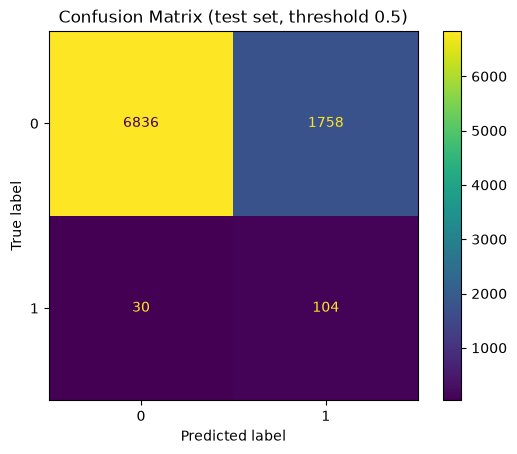

Training set
              precision    recall  f1-score   support

           0       0.99      0.80      0.89     34375
           1       0.05      0.72      0.10       536

    accuracy                           0.80     34911
   macro avg       0.52      0.76      0.49     34911
weighted avg       0.98      0.80      0.87     34911

Testing set
              precision    recall  f1-score   support

           0       1.00      0.80      0.88      8594
           1       0.06      0.78      0.10       134

    accuracy                           0.80      8728
   macro avg       0.53      0.79      0.49      8728
weighted avg       0.98      0.80      0.87      8728



In [43]:
# Best Model: Logistic Regression (class weight) + SelectFpr dengan hyperparameter hasil tuning
best_model = clone(tunning.best_estimator_)
best_model.fit(x_train, y_train)

# Model Prediction
y_train_pred = best_model.predict(x_train)
y_test_pred = best_model.predict(x_test)
y_train_proba = best_model.predict_proba(x_train)[:, 1]
y_test_proba = best_model.predict_proba(x_test)[:, 1]

# Evaluation Report
print("PR-AUC (training)  :", round(pr_auc_score(y_train, y_train_proba), 4))
print("PR-AUC (testing)   :", round(pr_auc_score(y_test, y_test_proba), 4), "| baseline acak (prevalensi test):", round(y_test.mean(), 4))
print("Recall (training)  :", round(recall_score(y_train, y_train_pred), 4))
print("Recall (testing)   :", round(recall_score(y_test, y_test_pred), 4))
print("F2 (training)      :", round(fbeta_score(y_train, y_train_pred, beta=2), 4))
print("F2 (testing)       :", round(fbeta_score(y_test, y_test_pred, beta=2), 4))
print("Savings (testing)  :", round(savings_usd(y_test, y_test_pred), 2), "USD (detail di Section 9)")

# Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.title("Confusion Matrix (test set, threshold 0.5)")
plt.show()

# Classification Report
print("Training set")
print(classification_report(y_train, y_train_pred))
print("Testing set")
print(classification_report(y_test, y_test_pred))

**Analisis Evaluasi Akhir** (threshold 0,5)
- **PR-AUC**: train 0,0787 vs test **0,0797**, atau ±5,2× di atas baseline acak (0,0154). Selisih train-test ≈ 0, tidak ada indikasi overfitting. Dengan hanya 134 klaim di test, nilai ini memiliki varians cukup besar.
- **Recall (test) 0,78** (train 0,72): dari 134 polis klaim, 104 terdeteksi dan 30 terlewat (FN).
- **F2 (test) 0,22** (train 0,21): rendah karena **precision hanya ±0,06**. Dari polis yang ditandai (104 TP + 1.735 FP), ±94% adalah FP. Accuracy turun ke 0,80 karena model sengaja dibuat sensitif.
- **Savings (test) -Rp 12,38 miliar** (rinci di Section 9): pada threshold 0,5 model lebih merugikan daripada tidak memakai model.
- Hasilnya hampir identik dengan versi 9 fitur, konsisten dengan temuan bahwa simplifikasi tidak mengubah model secara berarti.
- Kesimpulan: model berguna untuk **memprioritaskan/menyaring** polis (lift ±5×), tetapi tidak cukup tajam untuk menjadi dasar keputusan otomatis dengan struktur biaya ini.

## **7. Deployment**

In [44]:
import pickle

# Fitting a clone of the model with all dataset
# (clone dipakai agar best_model tetap hanya dilatih pada x_train untuk evaluasi/cost-benefit)
deploy_model = clone(best_model)
deploy_model.fit(x, y)

# Save to pickle object
with open("model_logreg_v1.sav", "wb") as file:
    pickle.dump(deploy_model, file)

data_clean = pd.read_csv('data_clean.csv')
data_clean.head()

,Agency,Product Name,Duration,Destination,Net Sales,Commission,Age,target
0,C2B,Annual Silver Plan,365,SINGAPORE,216.0,54.0,57,0
1,EPX,Cancellation Plan,4,MALAYSIA,10.0,0.0,33,0
2,JZI,Basic Plan,19,INDIA,22.0,7.7,26,0
3,EPX,2 way Comprehensive Plan,20,UNITED STATES,112.0,0.0,59,0
4,C2B,Bronze Plan,8,SINGAPORE,16.0,4.0,28,0


In [45]:
# Load model
with open('model_logreg_v1.sav', 'rb') as file:
    model = pickle.load(file)

# How to predict
feature = data_clean.drop('target', axis=1)
prediction_class = model.predict(feature)
prediction_prob = model.predict_proba(feature)[:,1]

print("Jumlah polis diprediksi klaim:", prediction_class.sum(), "dari", len(feature))
prediction_prob[:10]

Jumlah polis diprediksi klaim: 8787 dari 43639


array([0.87292012, 0.11044444, 0.24795947, 0.54203708, 0.75219978,
       0.10661481, 0.26035752, 0.28701018, 0.21690846, 0.25145603])

## **8. Model Interpretation**

### *8.1 Feature Importances*

,feature_names,coef,odds_ratio,abs_coef
0,Agency_C2B,1.048396,2.853070,1.048396
1,Agency_EPX,-0.887813,0.411555,0.887813
2,Agency_LWC,0.758782,2.135674,0.758782
3,Product Name_Bronze Plan,0.614221,1.848216,0.614221
4,Product Name_2 way Comprehensive Plan,0.603390,1.828307,0.603390
5,Product Name_Silver Plan,0.559288,1.749426,0.559288
6,Net Sales,0.497765,1.645041,0.497765
7,Product Name_Cancellation Plan,-0.485559,0.615353,0.485559
8,Agency_JZI,-0.358868,0.698467,0.358868
9,Product Name_Single Trip Travel Protect Platinum,0.336582,1.400154,0.336582


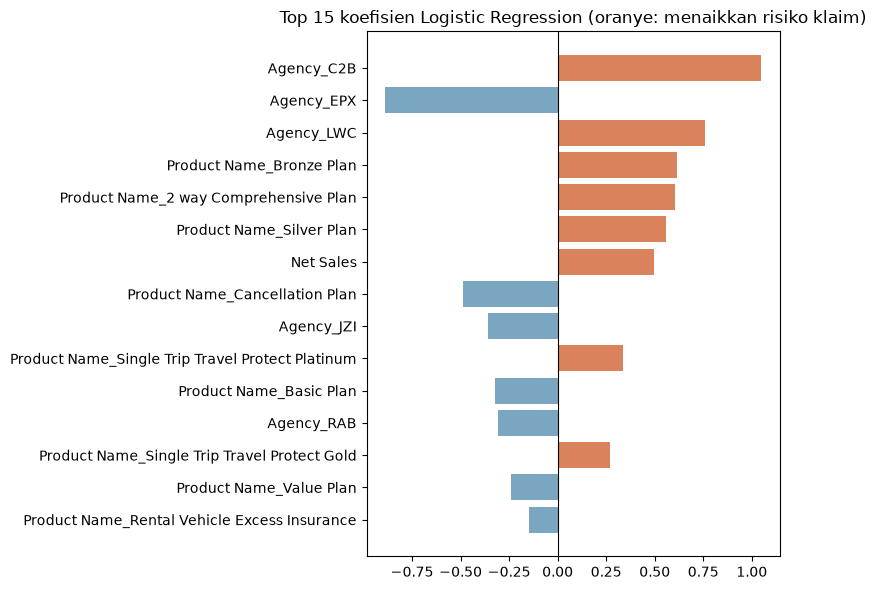

In [46]:
# Model berbasis Logistic Regression -> importance = koefisien (fitur sudah distandarkan / dummy)
# get coefficient from the model
coef = model.named_steps['model'].coef_[0]
# get feature names (setelah preprocessing + feature selection)
names = model[:-1].get_feature_names_out()

importances_score = pd.DataFrame({
    'feature_names': names,
    'coef': coef,
    'odds_ratio': np.exp(coef),
    'abs_coef': np.abs(coef)
})
importances_score = importances_score.sort_values('abs_coef', ascending=False).reset_index(drop=True)
display(importances_score.head(15))

top = importances_score.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top['feature_names'], top['coef'], color=np.where(top['coef'] > 0, '#d9825b', '#7aa6c2'))
plt.axvline(0, color='k', lw=0.8)
plt.title('Top 15 koefisien Logistic Regression (oranye: menaikkan risiko klaim)')
plt.tight_layout()
plt.show()

**Analisis Feature Importance (koefisien Logistic Regression)**
- Penaik risiko terbesar: **Agency_C2B** (koef. +1,05; odds ratio 2,85), **Agency_LWC** (+0,76; OR 2,14), produk **Bronze Plan**, **2 way Comprehensive Plan**, **Silver Plan** (OR ±1,75-1,85), dan **Net Sales** (+0,50; OR 1,64 per kenaikan 1 std).
- Penurun risiko: **Agency_EPX** (-0,89; OR 0,41), **Cancellation Plan** (-0,49; OR 0,62), Agency_JZI (OR 0,70), Basic Plan (OR 0,72).
- Koefisien dummy dibaca **relatif terhadap kategori referensi** (`drop='first'`). Agency dan Product Name saling tumpang tindih (V = 0,83), sehingga besar koefisien individualnya kurang stabil.
- Ini menjelaskan *model*, bukan sebab-akibat. "C2B" kemungkinan hanya proxy bagi karakteristik pelanggan/produk yang tidak terukur.

### *8.2 SHAP*

Background dataset has 43639 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=43639 when initializing the masker.


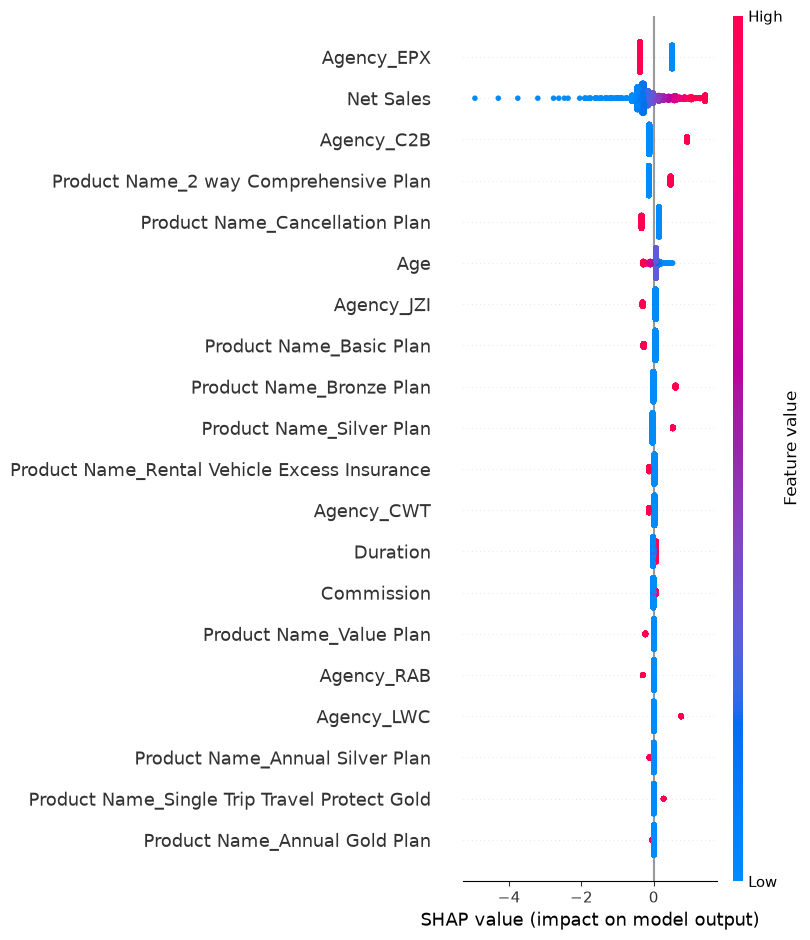

In [47]:
import shap

# get model from the pipeline
lr = model.named_steps['model']
# Get feature preprocessing (preprocessing + feature selection) and feature name from the pipeline
preprocess_select = model[:-1]
names = preprocess_select.get_feature_names_out()
# Transform feature
feature_pre = preprocess_select.transform(feature)

explainer = shap.LinearExplainer(lr, feature_pre, feature_perturbation='interventional')
sample_idx = feature_pre.sample(n=min(8000, len(feature_pre)), random_state=42).index
shap_values = explainer.shap_values(feature_pre.loc[sample_idx])

shap.summary_plot(shap_values, feature_pre.loc[sample_idx], feature_names=names)

**Analisis SHAP**
- Urutan pengaruh terbesar: **Agency_EPX**, **Net Sales**, **Agency_C2B**, **Product Name_Cancellation Plan**, **Product Name_2 way Comprehensive Plan**, lalu **Age**. Sejalan dengan koefisien dan EDA (untuk model linear, SHAP memang turunan dari koefisien).
- **Net Sales** adalah satu-satunya fitur numerik dengan pengaruh besar: premi tinggi mendorong prediksi klaim naik, premi rendah/negatif menurunkannya.
- **Age** berpengaruh kecil dan arahnya terbalik (usia lebih tinggi sedikit menurunkan prediksi). Karena Age banyak berisi nilai default 36, interpretasinya lemah (**perlu verifikasi**).
- Duration dan Commission hampir tidak berpengaruh setelah agensi, produk, dan Net Sales diperhitungkan. `Destination` tidak termasuk 20 fitur teratas SHAP.

## **9. Cost Benefit Simulation**

### *9.1 Implementasi Model*
1. **WHAT**: Model menyaring pemegang polis yang berpotensi mengajukan klaim.
2. **WHEN**: Setiap ada pembelian/penerbitan polis travel insurance baru.
3. **HOW**: Data polis -> `predict` -> polis berstatus *Claim* ditandai berisiko tinggi untuk ditindaklanjuti (mis. ditolak / ditinjau).

### *9.2 Risiko False Negative dan False Positive*
- **False Negative**: Pemegang polis yang akhirnya mengajukan klaim, tetapi tidak terprediksi oleh model (diprediksi tidak klaim). Perusahaan menanggung kerugian klaim tanpa antisipasi.
- **False Positive**: Pemegang polis yang sebenarnya tidak akan mengajukan klaim, tetapi diprediksi klaim oleh model. Polis ditolak/ditahan sehingga perusahaan kehilangan keuntungan dari polis tersebut (*loss opportunity*).

In [48]:
# Asumsi biaya sudah dihitung di Section 5.0 (dari data keseluruhan). Rekap:
print(f"Rata-rata Net Sales (premi)        : USD {avg_premium:,.2f} per polis")
print(f"Rata-rata % komisi thd Net Sales   : {commission_pct*100:.2f}%")
print(f"Keuntungan per polis               : USD {avg_premium * commission_pct:,.2f}")


Rata-rata Net Sales (premi)        : USD 40.42 per polis
Rata-rata % komisi thd Net Sales   : 23.65%
Keuntungan per polis               : USD 9.56


Dengan asumsi setiap pemegang polis membayar premi sejumlah rata-rata Net Sales dan keuntungan perusahaan sebesar rata-rata persentase komisi terhadap Net Sales, **dampak risikonya**:
- **False Negative**: Jika terdapat 1 pemegang polis yang FN, total kerugian yang didapatkan sejumlah premi polis tersebut (`COST_FN = avg_premium`).
- **False Positive**: Jika terdapat 1 pemegang polis yang FP, terjadi *loss opportunity* sebesar persentase komisi dari premi (`COST_FP = avg_premium x commission_pct`).

> Catatan: selain PR-AUC, evaluasi menekankan **Recall** dan **F2** (menekan FN lebih diutamakan karena COST_FN > COST_FP), dan hasilnya diterjemahkan ke Rupiah lewat cost-benefit.

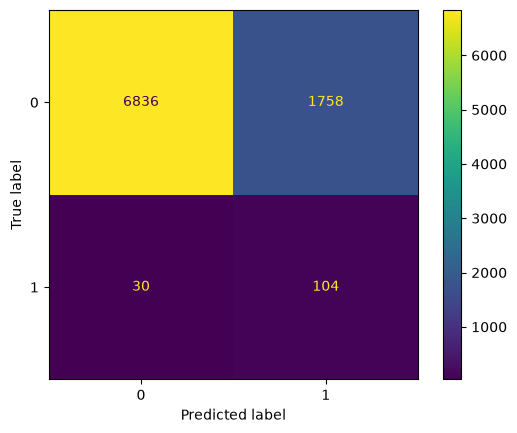

Total Polis (test set):  8728


In [49]:
# Prediction on test set (best_model dilatih hanya pada x_train, sehingga x_test benar-benar unseen)
y_test_pred = best_model.predict(x_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.show()

print("Total Polis (test set): ", len(y_test))

In [54]:
avg_premium = df["Net Sales"].mean()
avg_commission = df["Commission"].mean()
avg_margin = avg_premium - avg_commission
COST_FP = avg_margin


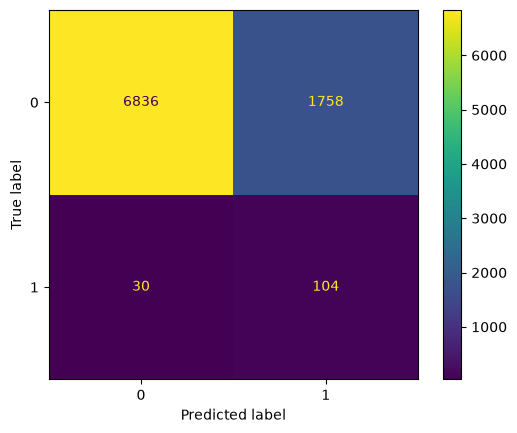

Total Polis (test set):  8728
                 COST-BENEFIT ANALYSIS REPORT                  
• Total Kasus Uji (Test Set)            : 8,728 Polis
• Jumlah Polis Aktual Klaim             : 134 Polis
• COST_FN (per polis)                   : USD 2,609.00
• COST_FP (per polis)                   : USD 30.86
--------------------------------------------------------------------
Loss TANPA Model ML (BASELINE)          : USD 349,606.00 (Rp 6,292,908,000.00)
Polis Klaim Tak Terprediksi             | 134 x 2,609.00 : USD 349,606.00

Loss dengan Logistic Regression         : USD 132,517.45 (Rp 2,385,314,133.58)
Polis Klaim Tak Terprediksi (FN)        | 30 x 2,609.00 : USD 78,270.00
Polis Tidak Klaim Terprediksi Klaim (FP)| 1,758 x 30.86 : USD 54,247.45
--------------------------------------------------------------------
ESTIMASI PENGHEMATAN FINANSIAL          : USD 217,088.55 (Rp 3,907,593,866.42 )
Efisiensi Penekanan Kerugian            : 62.10%


In [58]:
# Prediction on test set (best_model dilatih hanya pada x_train, sehingga x_test benar-benar unseen)
y_test_pred = best_model.predict(x_test)

ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred)
plt.show()

print("Total Polis (test set): ", len(y_test))

# 1. Konstanta Biaya (Cost) COST_FP dan COST_FN sudah didefinisikan di Section 5.0

# 2. Buat DataFrame ringkas untuk evaluasi
df_cost = pd.DataFrame({
    'Actual': y_test,
    'Tanpa Model': np.zeros(len(y_test)),
    'Prediksi Logreg': y_test_pred
})

# --- A. Skenario: TANPA MODEL (Baseline) ---
fp_tanpa_model = 0
fn_tanpa_model = np.sum((df_cost['Actual'] == 1) & (df_cost['Tanpa Model'] == 0))
loss_tanpa_model = (fp_tanpa_model * COST_FP) + (fn_tanpa_model * COST_FN)

# --- B. Skenario: DENGAN MODEL Logistic Regression ---
fp_lr = np.sum((df_cost['Actual'] == 0) & (df_cost['Prediksi Logreg'] == 1))
fn_lr = np.sum((df_cost['Actual'] == 1) & (df_cost['Prediksi Logreg'] == 0))
loss_lr = (fp_lr * COST_FP) + (fn_lr * COST_FN)

# --- C. Hitung Penghematan (Savings) ---
total_savings = loss_tanpa_model - loss_lr
savings_percentage = (total_savings / loss_tanpa_model) * 100

# ==============================================================================
# CETAK HASIL BUSINESS INSIGHT (DALAM SATUAN USD)
# ==============================================================================
print("="*68)
print("                 COST-BENEFIT ANALYSIS REPORT                  ")
print("="*68)
print(f"• Total Kasus Uji (Test Set)            : {len(df_cost):,} Polis")
print(f"• Jumlah Polis Aktual Klaim             : {np.sum(df_cost['Actual'] == 1):,} Polis")
print(f"• COST_FN (per polis)                   : USD {COST_FN:,.2f}")
print(f"• COST_FP (per polis)                   : USD {COST_FP:,.2f}")
print("-"*68)
print(f"Loss TANPA Model ML (BASELINE)          : USD {loss_tanpa_model:,.2f} (Rp {loss_tanpa_model*18000:,.2f})")
print(f"Polis Klaim Tak Terprediksi             | {fn_tanpa_model:,} x {COST_FN:,.2f} : USD {loss_tanpa_model:,.2f}")
print()
print(f"Loss dengan Logistic Regression         : USD {loss_lr:,.2f} (Rp {loss_lr*18000:,.2f})")
print(f"Polis Klaim Tak Terprediksi (FN)        | {fn_lr:,} x {COST_FN:,.2f} : USD {fn_lr * COST_FN:,.2f}")
print(f"Polis Tidak Klaim Terprediksi Klaim (FP)| {fp_lr:,} x {COST_FP:,.2f} : USD {fp_lr * COST_FP:,.2f}")
print("-"*68)
print(f"ESTIMASI PENGHEMATAN FINANSIAL          : USD {total_savings:,.2f} (Rp {total_savings*18000:,.2f} )")
print(f"Efisiensi Penekanan Kerugian            : {savings_percentage:.2f}%")
print("="*68)

**Kesimpulan Cost Benefit Simulation**
- Dengan asumsi premi = rata-rata Net Sales (**USD 36,51**) dan keuntungan = 22,59% dari premi (**USD 8,25**), biaya FN : FP = ±4,4 : 1. Titik impas precision = COST_FP / (COST_FP + COST_FN) ≈ **18%**.
- **Tanpa model**: 116 klaim tak terdeteksi, kerugian **USD 4.235,48**.
- **Dengan model**: FN turun dari 116 menjadi 37 (kerugian FN USD 1.350,97), tetapi muncul **1.545 FP** dengan loss opportunity **USD 12.744,88**. Total kerugian **USD 14.095,85**.
- **Hasil: penghematan -USD 9.860,37 (-232,8%)**. Pada asumsi dan threshold 0,5 ini, **model justru merugikan** dibanding tanpa model.
- Penyebabnya: precision model (±5%) jauh di bawah titik impas (±18%). Meski recall dan F2 menunjukkan model "menangkap" klaim, jumlah FP terlalu besar karena prevalensi klaim hanya 1,4%. Recall dan F2 tidak memperhitungkan besarnya biaya FP absolut, sehingga model bisa tampak baik pada keduanya tetapi tetap merugi pada cost-benefit.
- Pergantian satuan (Rp juta -> USD) hanya mengubah **skala** angka; rasio FN : FP, titik impas precision, dan kesimpulan arah (model merugi) ditentukan oleh rasio tersebut dan tidak bergantung pada mata uang. Angka absolutnya menjadi jauh lebih kecil (ribuan USD pada 8.547 polis test).
- **Keterbatasan asumsi (perlu verifikasi)**: (1) `COST_FN` = premi mengikuti pemetaan contoh, padahal kerugian FN sebenarnya adalah nilai klaim yang dibayarkan, dan nilai klaim tidak ada di dataset; (2) komisi pada data adalah biaya yang dibayar ke agensi, bukan keuntungan perusahaan, sehingga `COST_FP` bisa over/underestimate; (3) `Net Sales` dan `Commission` diperlakukan sebagai USD sesuai instruksi, padahal dataset tidak mencantumkan mata uang secara eksplisit; (4) hanya 116 klaim di test sehingga angka ini berfluktuasi besar; (5) 91 klaim dengan Duration > 365 hari sudah dikeluarkan dari data (Section 2.4), sehingga hasil ini tidak mewakili polis tahunan berdurasi panjang.
- Hasil negatif ini bergantung pada aksi yang diasumsikan (polis yang ditandai kehilangan seluruh keuntungannya) dan pada threshold 0,5. Bila aksinya lebih murah (mis. verifikasi manual atau premium loading), atau threshold dipilih dari perhitungan biaya, titik impas dan hasilnya bisa berbeda.
